# EC_Sprint_3_DaisyCare_Grupo_Rodrigo_ML

Notebook estruturado para atender integralmente aos requisitos da disciplina **Machine Learning & Data Science** na Sprint 3 do Challenge MaterDei.

Turma: 2TSCPR_NOTURNO

Integrantes:

André Alves de Jesus  – RM 559943

Diego Toshio Horoiwa – RM 560860

Felipe Pacheco da Silva – RM 559234

Rodrigo da Costa Nillo – RM 559947

Este material foi organizado como **relatório técnico completo + código executável**, combinando:
- contextualização do problema;
- análise exploratória e pré-processamento;
- limpeza, imputação e tratamento de outliers;
- engenharia de atributos;
- codificação e normalização;
- comparação de modelos;
- validação cruzada;
- otimização de hiperparâmetros;
- avaliação de desempenho;
- interpretabilidade do modelo final;
- função de predição para MVP local.

> **Observação importante:** este notebook foi estruturado para rodar no mesmo diretório dos arquivos:
> - `dataset_01_agendamentos_conversao_200k.parquet`
> - `dataset_02_experiencia_qualidade_200k.parquet`
> - `dataset_03_logs_daisy_n8n_IA_logistica_200k.parquet`


## Guia de aderência aos critérios do professor

Este notebook foi organizado para atender explicitamente aos itens exigidos na disciplina:

### A. Análise Exploratória e Pré-processamento
- limpeza e tratamento de dados;
- diagnóstico e imputação de valores ausentes;
- detecção e manipulação de outliers;
- criação e justificativa de novas features;
- codificação de variáveis categóricas e normalização de variáveis numéricas.

### B. Implementação e Treinamento do Modelo
- comparação e justificativa de pelo menos dois algoritmos;
- divisão treino/teste;
- validação cruzada para robustez e redução de overfitting;
- otimização de hiperparâmetros com evidência no código.

### C. Avaliação de Desempenho
- métricas adequadas ao problema de conversão;
- interpretação dos resultados;
- análise visual da importância das variáveis;
- conclusão técnica e executiva.

.


In [1]:
# Instalação opcional
%pip install pyarrow plotly scikit-learn -q

.

In [2]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedShuffleSplit,
    cross_validate, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.base import clone

import plotly.express as px

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
sns.set_style('whitegrid')

RANDOM_STATE = 42

.

## 1. Leitura das bases

In [3]:
DATA_DIR = Path('.')

def read_parquet_safe(path: Path) -> pd.DataFrame:
    '''
    Faz leitura robusta de parquet.
    Primeiro tenta pandas.
    Se houver problema de ambiente com pyarrow/pandas extension types,
    usa leitura direta via pyarrow.
    '''
    try:
        return pd.read_parquet(path)
    except Exception:
        import pyarrow.parquet as pq
        return pq.read_table(path).to_pandas()

def load_any(base_name: str) -> pd.DataFrame:
    parquet_path = DATA_DIR / f'{base_name}.parquet'
    csv_matches = sorted(DATA_DIR.glob(f'{base_name}*.csv'))

    if parquet_path.exists():
        return read_parquet_safe(parquet_path)

    if csv_matches:
        return pd.read_csv(csv_matches[0])

    raise FileNotFoundError(f'Arquivo não encontrado para base: {base_name}')

df1 = load_any('dataset_01_agendamentos_conversao_200k')
df2 = load_any('dataset_02_experiencia_qualidade_200k')
df3 = load_any('dataset_03_logs_daisy_n8n_IA_logistica_200k')

for col in ['data_agendamento', 'data_consulta_prevista']:
    if col in df1.columns:
        df1[col] = pd.to_datetime(df1[col], errors='coerce')

for col in ['data_hora_evento', 'data_evento']:
    if col in df3.columns:
        df3[col] = pd.to_datetime(df3[col], errors='coerce')

print('Dataset 01:', df1.shape)
print('Dataset 02:', df2.shape)
print('Dataset 03:', df3.shape)


Dataset 01: (200000, 36)
Dataset 02: (200000, 12)
Dataset 03: (200000, 37)


.

In [4]:
display(df1.head(10))

,id_paciente,id_agendamento,id_unidade,unidade,cidade,estado,idade,sexo,especialidade,tipo_servico,...,score_regra_no_show,status_agendamento,target_conversao,no_show,cancelado,remarcado,ticket_estimado,fila_encaixe_habilitada,raio_disponibilidade_km,aceitaria_encaixe_ultima_hora
0,1,AG0000001,1,Mater Dei Santo Agostinho,Contagem,MG,27,F,Dermatologia,Exame,...,76.0,Cancelado,0,0,1,0,312.88,0,NaN,0
1,2,AG0000002,2,Mater Dei Goiânia,Goiânia,GO,78,F,Ortopedia,Exame,...,68.7,Realizado,1,0,0,0,1029.22,0,NaN,0
2,3,AG0000003,3,Mater Dei Salvador,Salvador,BA,41,M,Cardiologia,Exame,...,80.3,No-Show,0,1,0,0,612.48,0,NaN,0
3,4,AG0000004,4,Mater Dei Contorno,Betim,MG,23,F,Neurologia,Exame,...,99.0,Cancelado,0,0,1,0,375.64,0,NaN,0
4,5,AG0000005,1,Mater Dei Santo Agostinho,Belo Horizonte,MG,70,M,Ortopedia,Consulta,...,60.0,Realizado,1,0,0,0,174.96,0,NaN,0
5,6,AG0000006,1,Mater Dei Santo Agostinho,Belo Horizonte,MG,38,F,Ortopedia,Consulta,...,92.4,Realizado,1,0,0,0,588.79,0,NaN,0
6,7,AG0000007,4,Mater Dei Contorno,Belo Horizonte,MG,0,F,Cardiologia,Exame,...,81.1,Realizado,1,0,0,0,634.13,1,10.0,0
7,8,AG0000008,2,Mater Dei Goiânia,Goiânia,GO,71,M,Neurologia,Consulta,...,87.3,Realizado,1,0,0,0,375.77,1,10.0,1
8,9,AG0000009,4,Mater Dei Contorno,Betim,MG,32,F,Oncologia,Consulta,...,87.2,Realizado,1,0,0,0,507.70,1,5.0,0
9,10,AG0000010,3,Mater Dei Salvador,Salvador,BA,30,F,Ginecologia,Exame,...,74.3,Realizado,1,0,0,0,1135.92,0,NaN,0


.

In [5]:
display(df2.head(10))

,id_agendamento,id_paciente,tempo_espera_min,nota_atendimento_1a5,nota_profissional_1a5,nota_hospital_1a5,resolucao_primeiro_contato,nps_0a100,categoria_reclamacao,sentimento_mensagem,tempo_resposta_min,avaliacao_textual
0,AG0000001,1,37,3,3,4,1,76,Cobrança,Positivo,18,Atendimento satisfatório e processo concluído ...
1,AG0000002,2,25,4,4,4,0,41,Cobrança,Negativo,12,Paciente reportou insatisfação relacionada ao ...
2,AG0000003,3,34,3,5,5,0,58,Nenhuma,Neutro,9,Atendimento satisfatório e processo concluído ...
3,AG0000004,4,50,3,5,4,1,63,Nenhuma,Neutro,16,Atendimento satisfatório e processo concluído ...
4,AG0000005,5,28,5,5,3,0,100,Nenhuma,Positivo,7,Paciente reportou insatisfação relacionada ao ...
5,AG0000006,6,28,3,5,4,1,93,Nenhuma,Positivo,21,Atendimento satisfatório e processo concluído ...
6,AG0000007,7,14,5,3,4,0,51,Nenhuma,Positivo,18,Atendimento satisfatório e processo concluído ...
7,AG0000008,8,23,5,5,5,0,73,Nenhuma,Positivo,34,Paciente reportou insatisfação relacionada ao ...
8,AG0000009,9,41,4,4,5,1,71,Nenhuma,Positivo,11,Atendimento satisfatório e processo concluído ...
9,AG0000010,10,12,5,4,5,1,51,Cobrança,Negativo,2,Atendimento satisfatório e processo concluído ...


.


In [6]:
display(df3.head(10))

,id_log,id_agendamento,id_paciente_candidato,data_hora_evento,data_evento,workflow_n8n,evento,tipo_origem_vaga,status_execucao,latencia_ms,...,engajamento_paciente_score,paciente_apto,motivo_inaptidao,score_viabilidade,convite_enviado_flag,convite_aceito_flag,encaixe_confirmado_flag,tempo_resposta_convite_min,flag_smart_queue,mensagem_resumo
0,LOG00000001,AG0121959,PAC0176911,2026-04-15 08:09:00,2026-04-15,Smart Queue,smart_queue_acionada,cancelamento,sucesso,948,...,0.94,1,Apto,0.90,0,0,0,NaN,1,Cancelamento detectado; transporte recomendado...
1,LOG00000002,AG0146868,PAC0070585,2026-03-06 16:06:00,2026-03-06,Smart Queue,pacientes_aptos,cancelamento,sucesso,835,...,0.33,0,Tempo insuficiente para deslocamento,0.62,0,0,0,NaN,1,Cancelamento detectado; transporte recomendado...
2,LOG00000003,AG0131933,PAC0033892,2026-02-13 22:32:00,2026-02-13,Smart Queue,convite_enviado,remarcacao,sucesso,794,...,0.66,1,Apto,0.79,1,0,0,8.6,1,Remarcacao detectado; transporte recomendado: ...
3,LOG00000004,AG0103695,PAC0072676,2026-03-09 07:45:00,2026-03-09,Smart Queue,encaixe_confirmado,remarcacao,sucesso,620,...,0.41,1,Apto,0.83,1,1,1,7.3,1,Remarcacao detectado; transporte recomendado: ...
4,LOG00000005,AG0119880,PAC0043899,2026-02-21 04:21:00,2026-02-21,Smart Queue,pacientes_aptos,cancelamento,sucesso,728,...,0.73,1,Apto,0.90,0,0,0,NaN,1,Cancelamento detectado; transporte recomendado...
5,LOG00000006,AG0110269,PAC0127456,2026-02-14 02:42:00,2026-02-14,Smart Queue,vaga_liberada,remarcacao,sucesso,1009,...,0.83,1,Apto,0.79,0,0,0,NaN,1,Remarcacao detectado; transporte recomendado: ...
6,LOG00000007,AG0054887,PAC0016534,2026-04-21 02:57:00,2026-04-21,Smart Queue,vaga_liberada,remarcacao,sucesso,528,...,0.76,0,Tempo insuficiente para deslocamento,0.70,0,0,0,NaN,1,Remarcacao detectado; transporte recomendado: ...
7,LOG00000008,AG0137338,PAC0088883,2026-01-08 15:21:00,2026-01-08,Smart Queue,vaga_liberada,remarcacao,sucesso,855,...,0.68,0,Sem interesse em encaixe,0.70,0,0,0,NaN,1,Remarcacao detectado; transporte recomendado: ...
8,LOG00000009,AG0168267,PAC0014575,2026-02-11 10:36:00,2026-02-11,Smart Queue,smart_queue_acionada,cancelamento,sucesso,818,...,0.75,0,Sem interesse em encaixe,0.67,0,0,0,NaN,1,Cancelamento detectado; transporte recomendado...
9,LOG00000010,AG0087499,PAC0006914,2026-03-19 23:05:00,2026-03-19,Smart Queue,pacientes_elegiveis,cancelamento,sucesso,642,...,0.57,0,Sem interesse em encaixe,0.68,0,0,0,NaN,1,Cancelamento detectado; transporte recomendado...


.

## 2. Contexto dos dados e decisão anti-vazamento

Neste projeto, o objetivo é prever a **probabilidade de conversão do agendamento** com base em informações disponíveis antes da realização do atendimento.

Por isso, variáveis que representam o desfecho final ou informações muito próximas do evento real foram tratadas com cuidado para evitar **data leakage**.

Exemplos de atenção:
- `target_conversao`, `no_show`, `status_agendamento` não entram como preditoras;
- identificadores são removidos;
- a análise executiva destaca que `confirmou_24h`, `confirmou_4h` e `confirmou_2h` são úteis, mas devem ser interpretadas conforme a janela operacional da previsão.

.

## 3. Análise Exploratória dos Dados (EDA)

Nesta etapa, foi realizada uma análise exploratória para compreender o comportamento das variáveis, verificar padrões iniciais e identificar relações relevantes com a variável alvo.

O EDA foi reorganizado para melhorar a fluidez visual do notebook, reduzindo a repetição de gráficos de barras e equilibrando o uso de histogramas, boxplots, mapas de calor e gráficos de pontos. Isso torna a leitura mais agradável e intuitiva


In [7]:
df_eda = df1.copy()
print(df_eda.shape)

(200000, 36)


.

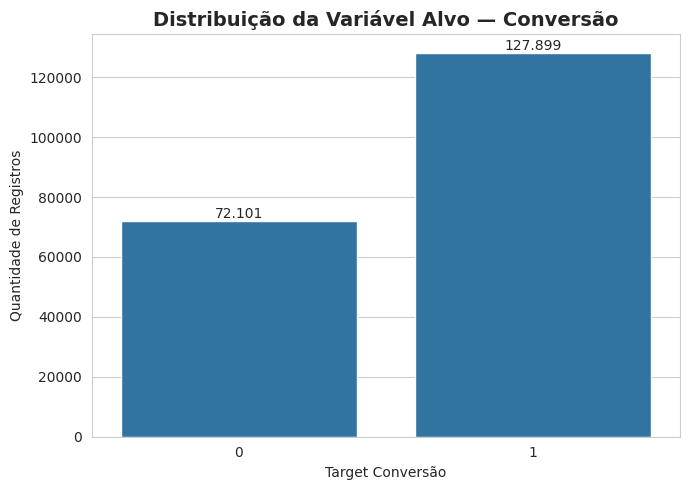

In [8]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=df_eda['target_conversao'])
plt.title('Distribuição da Variável Alvo — Conversão', fontsize=14, weight='bold')
plt.xlabel('Target Conversão')
plt.ylabel('Quantidade de Registros')

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}'.replace(',', '.'),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretação:**  
A distribuição da variável alvo permite avaliar se existe equilíbrio entre as classes de conversão. Essa análise orienta a escolha correta das métricas e da estratégia de modelagem.

.

### Painel de Histogramas das Variáveis Numéricas

Nesta etapa, são apresentadas distribuições das principais variáveis numéricas do conjunto de dados. O objetivo é observar concentração, dispersão, assimetria e possíveis comportamentos extremos, apoiando a interpretação inicial dos dados antes da modelagem.

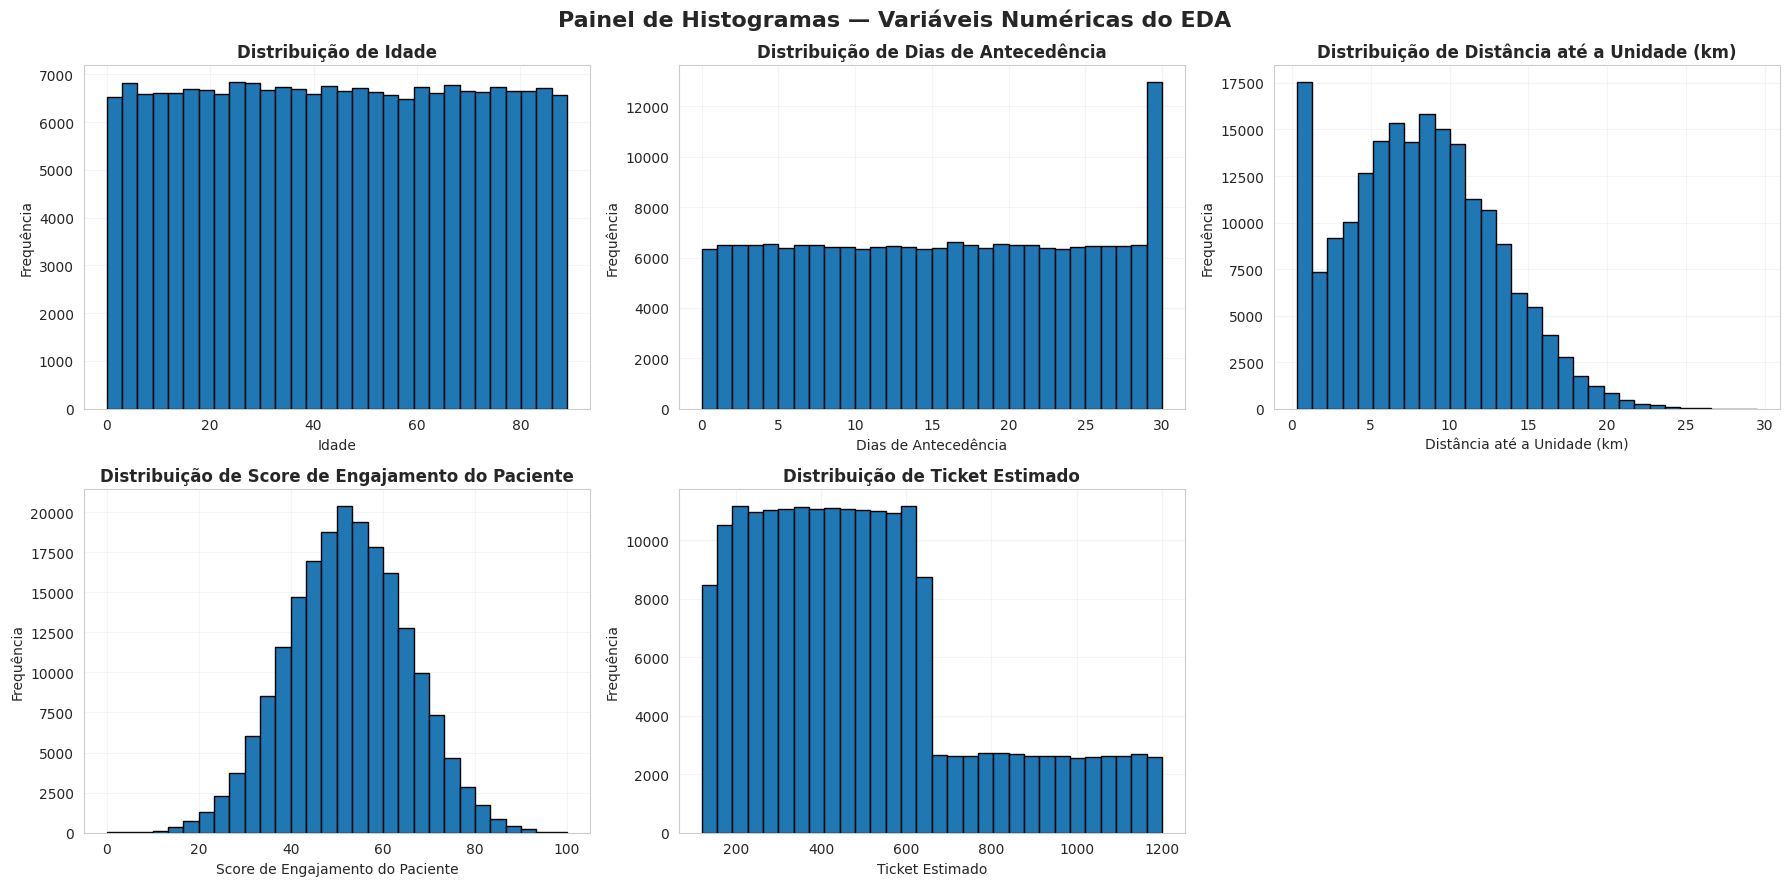

In [9]:
# Histograma - painel de variáveis numéricas
num_hist = ['idade', 'dias_antecedencia', 'distancia_km', 'score_engajamento_paciente', 'ticket_estimado']

nomes_bonitos = {
    'idade': 'Idade',
    'dias_antecedencia': 'Dias de Antecedência',
    'distancia_km': 'Distância até a Unidade (km)',
    'score_engajamento_paciente': 'Score de Engajamento do Paciente',
    'ticket_estimado': 'Ticket Estimado'
}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(num_hist):
    if col in df_eda.columns:
        axes[i].hist(df_eda[col].dropna(), bins=30, edgecolor='black')
        axes[i].set_title(f'Distribuição de {nomes_bonitos[col]}', fontsize=12, weight='bold')
        axes[i].set_xlabel(nomes_bonitos[col])
        axes[i].set_ylabel('Frequência')
        axes[i].grid(alpha=0.2)

for j in range(len(num_hist), len(axes)):
    axes[j].axis('off')

plt.suptitle('Painel de Histogramas — Variáveis Numéricas do EDA', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

**Interpretação:**  
O painel de histogramas permite analisar como as variáveis numéricas se distribuem no conjunto de dados. Essa visualização ajuda a identificar padrões importantes, como assimetria, concentração de valores, caudas longas e possíveis outliers, contribuindo para uma compreensão mais completa do comportamento da base.

.

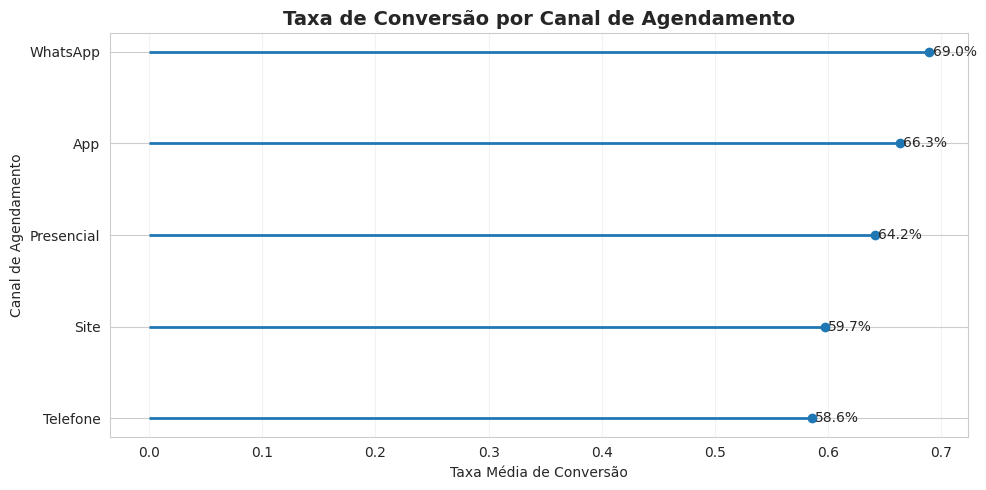

In [10]:
conv_canal = (
    df_eda.groupby('canal_agendamento')['target_conversao']
    .mean()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hlines(y=conv_canal.index, xmin=0, xmax=conv_canal.values, linewidth=2)
ax.plot(conv_canal.values, conv_canal.index, 'o')
ax.set_title('Taxa de Conversão por Canal de Agendamento', fontsize=14, weight='bold')
ax.set_xlabel('Taxa Média de Conversão')
ax.set_ylabel('Canal de Agendamento')
ax.grid(axis='x', alpha=0.25)

for y, x in enumerate(conv_canal.values):
    ax.text(x + 0.003, y, f'{x:.1%}', va='center', fontsize=10)

plt.tight_layout()
plt.show()


**Interpretação:**  
O gráfico de pontos evidencia com mais clareza as diferenças de conversão entre os canais de agendamento. Esse formato reduz a poluição visual e facilita a comparação direta entre alternativas operacionais.


.

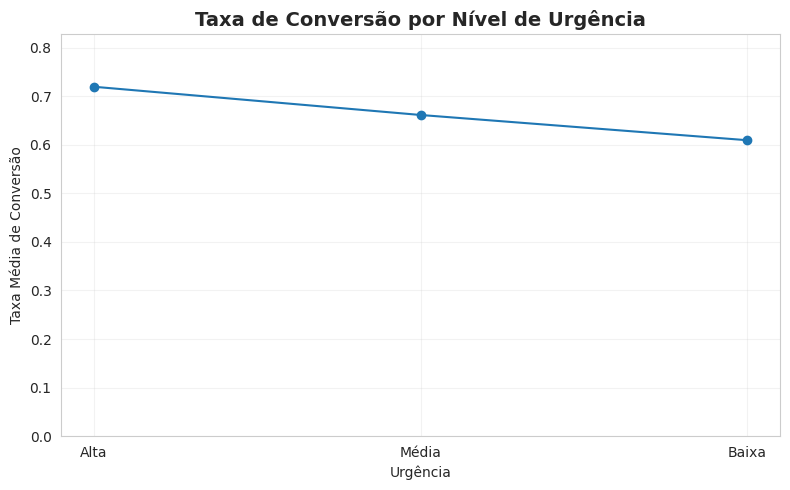

In [11]:
conv_urg = (
    df_eda.groupby('urgencia')['target_conversao']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.plot(conv_urg['urgencia'], conv_urg['target_conversao'], marker='o')
plt.title('Taxa de Conversão por Nível de Urgência', fontsize=14, weight='bold')
plt.xlabel('Urgência')
plt.ylabel('Taxa Média de Conversão')
plt.ylim(0, min(1, conv_urg['target_conversao'].max() * 1.15))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretação:**  
A visualização em linha com marcadores deixa mais evidente a variação da conversão entre os níveis de urgência. Em vez de apenas comparar alturas, o gráfico ajuda a perceber a direção e a intensidade dessa diferença.


.

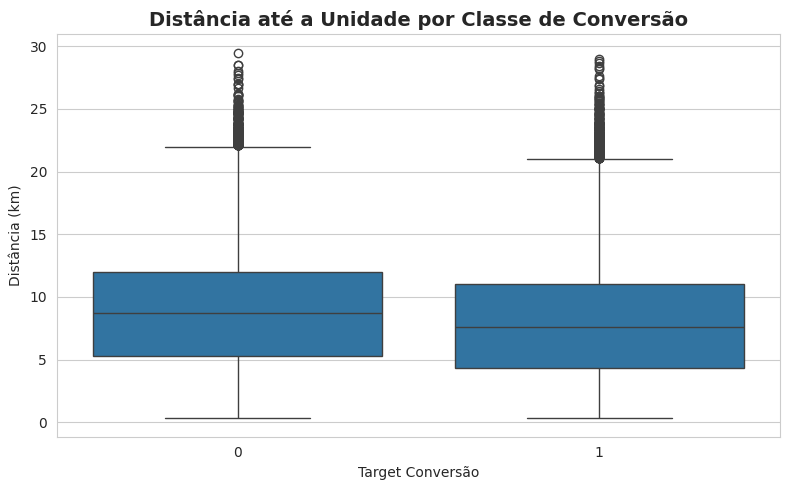

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_eda, x='target_conversao', y='distancia_km')
plt.title('Distância até a Unidade por Classe de Conversão', fontsize=14, weight='bold')
plt.xlabel('Target Conversão')
plt.ylabel('Distância (km)')
plt.tight_layout()
plt.show()

**Interpretação:**  
A distância até a unidade é um fator operacional importante. O boxplot permite observar diferenças de distribuição entre convertidos e não convertidos, além da presença de outliers.

.

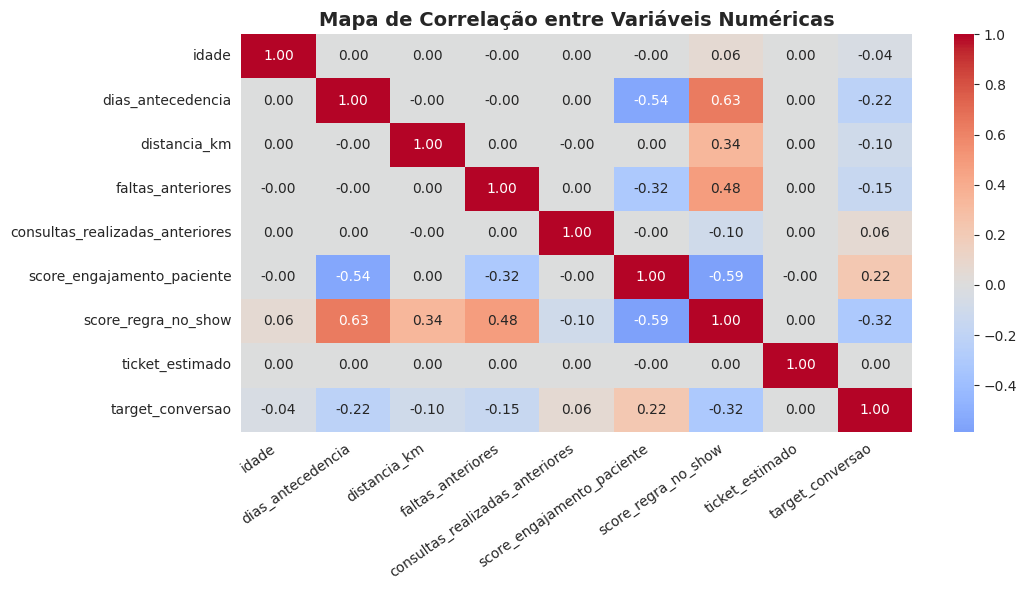

In [13]:
corr_cols = [
    'idade', 'dias_antecedencia', 'distancia_km', 'faltas_anteriores',
    'consultas_realizadas_anteriores', 'score_engajamento_paciente',
    'score_regra_no_show', 'ticket_estimado', 'target_conversao'
]
corr_cols = [c for c in corr_cols if c in df_eda.columns]

corr = df_eda[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(11, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Mapa de Correlação entre Variáveis Numéricas', fontsize=14, weight='bold')
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretação:**  
O heatmap mostra a intensidade e a direção das relações lineares entre as variáveis numéricas. Ele ajuda a identificar padrões iniciais e potenciais atributos relevantes para o modelo.

### Fechamento da Análise Exploratória

A etapa exploratória mostrou que o problema possui sinal estatístico relevante, com relações perceptíveis entre perfil do paciente, contexto do agendamento, histórico anterior e probabilidade de conversão.

.

## 4. Engenharia de Atributos

Nesta etapa, foram utilizadas variáveis derivadas e transformações seguras com o objetivo de aumentar a capacidade explicativa do conjunto de dados, sem introduzir vazamento de informação.

In [14]:
df = df1.copy()

df['dias_para_consulta_calc'] = (df['data_consulta_prevista'] - df['data_agendamento']).dt.days
df['indice_confirmacao'] = df[['confirmou_24h', 'confirmou_4h', 'confirmou_2h']].fillna(0).sum(axis=1)
df['taxa_faltas_historica'] = df['faltas_anteriores'] / (df['consultas_realizadas_anteriores'] + 1)
df['engajamento_vs_risco'] = df['score_engajamento_paciente'] - df['score_regra_no_show']
df['mes_consulta'] = df['data_consulta_prevista'].dt.month
df['dia_semana_num'] = df['data_consulta_prevista'].dt.dayofweek

df['faixa_idade_ml'] = pd.cut(
    df['idade'],
    bins=[0, 18, 25, 30, 35, 40, 45, 50, 55, 60, 65, 120],
    labels=['0-18', '19-25', '26-30', '31-35', '36-40', '41-45', '46-50', '51-55', '56-60', '61-65', '65+']
)

display(df[['dias_para_consulta_calc', 'indice_confirmacao', 'taxa_faltas_historica',
            'engajamento_vs_risco', 'mes_consulta', 'dia_semana_num', 'faixa_idade_ml']].head())

,dias_para_consulta_calc,indice_confirmacao,taxa_faltas_historica,engajamento_vs_risco,mes_consulta,dia_semana_num,faixa_idade_ml
0,20,2,0.000000,-17.3,2,4,26-30
1,8,3,0.000000,1.8,2,6,65+
2,24,2,0.000000,-52.8,2,0,41-45
3,15,2,0.285714,-52.7,2,6,19-25
4,8,2,0.000000,-14.1,4,2,65+


.


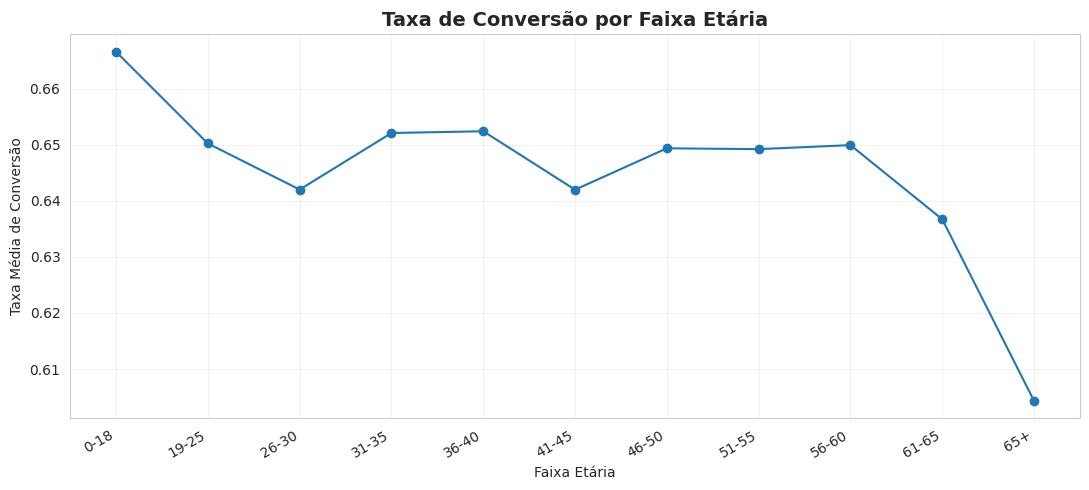

In [15]:
conv_faixa = (
    df.groupby('faixa_idade_ml', observed=False)['target_conversao']
    .mean()
    .sort_index()
    .reset_index()
)

plt.figure(figsize=(11, 5))
plt.plot(conv_faixa['faixa_idade_ml'], conv_faixa['target_conversao'], marker='o')
plt.title('Taxa de Conversão por Faixa Etária', fontsize=14, weight='bold')
plt.xlabel('Faixa Etária')
plt.ylabel('Taxa Média de Conversão')
plt.xticks(rotation=30, ha='right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretação:**  
A evolução da taxa de conversão por faixa etária permite comparar grupos de forma mais limpa do que um gráfico de barras. A leitura em linha facilita perceber tendências graduais e possíveis faixas com comportamento mais favorável ou mais crítico para a conversão.


.

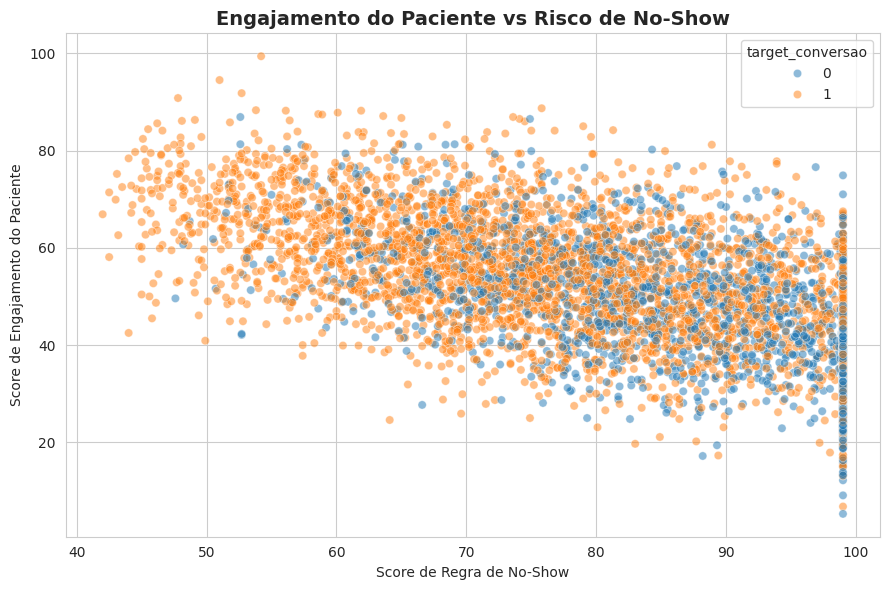

In [16]:
sample_plot = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sample_plot,
    x='score_regra_no_show',
    y='score_engajamento_paciente',
    hue='target_conversao',
    alpha=0.5
)
plt.title('Engajamento do Paciente vs Risco de No-Show', fontsize=14, weight='bold')
plt.xlabel('Score de Regra de No-Show')
plt.ylabel('Score de Engajamento do Paciente')
plt.tight_layout()
plt.show()

**Interpretação:**  
A relação entre engajamento e risco de no-show ajuda a entender como variáveis comportamentais e operacionais interagem na separação das classes.

.

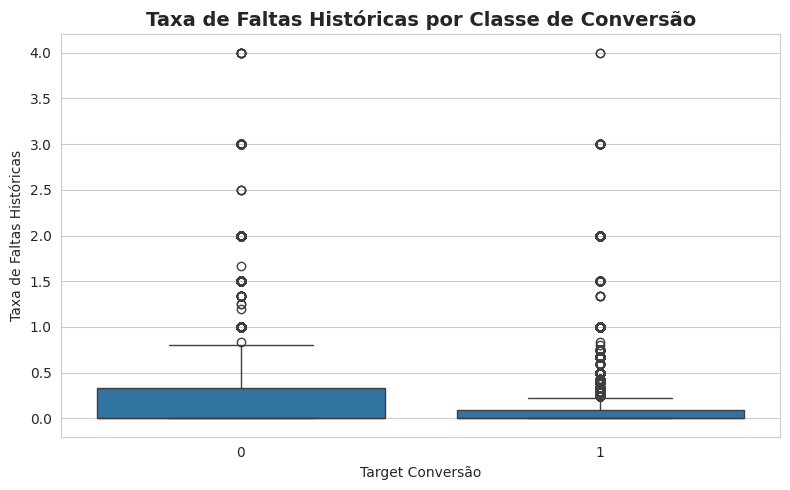

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='target_conversao', y='taxa_faltas_historica')
plt.title('Taxa de Faltas Históricas por Classe de Conversão', fontsize=14, weight='bold')
plt.xlabel('Target Conversão')
plt.ylabel('Taxa de Faltas Históricas')
plt.tight_layout()
plt.show()

**Interpretação:**  
O histórico de faltas é um dos sinais mais importantes para a modelagem, pois representa comportamento passado do paciente e tende a refletir recorrência.

### Fechamento da Engenharia de Atributos

As variáveis derivadas ampliaram a qualidade analítica da base ao representarem idade, comportamento histórico, engajamento e risco operacional de forma mais interpretável.

.



## 4.1 Diagnóstico de Valores Ausentes

Antes da etapa de modelagem, foi realizado um diagnóstico explícito de valores ausentes para identificar a magnitude do problema e justificar a estratégia de imputação utilizada posteriormente no pipeline.

A decisão adotada foi:
- **mediana** para variáveis numéricas, por ser mais robusta a assimetria e valores extremos;
- **categoria mais frequente** para variáveis categóricas, preservando coerência e simplicidade operacional.

,qtd_missing,pct_missing
raio_disponibilidade_km,144365,72.18
faixa_idade_ml,2165,1.08
id_paciente,0,0.00
id_agendamento,0,0.00
id_unidade,0,0.00
unidade,0,0.00
cidade,0,0.00
estado,0,0.00
idade,0,0.00
sexo,0,0.00


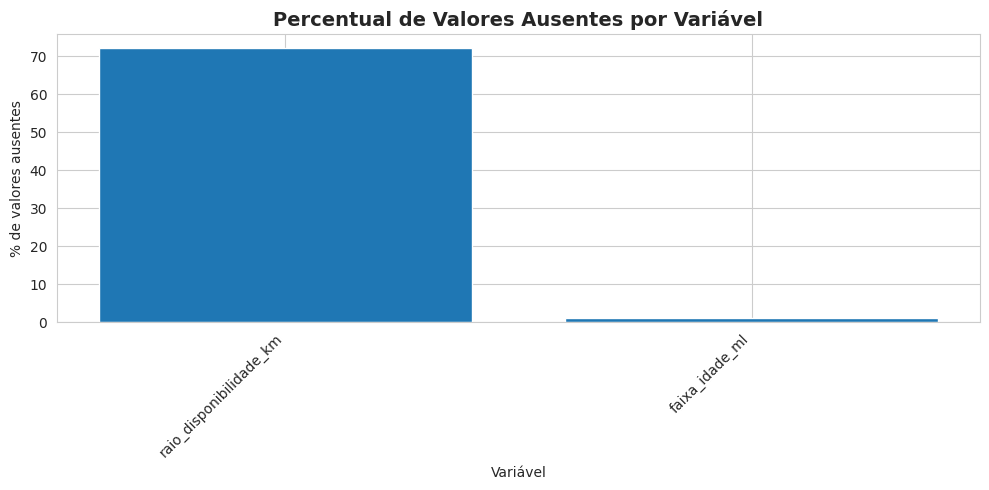

In [18]:
missing_summary = (
    df.isna()
      .sum()
      .rename('qtd_missing')
      .to_frame()
)

missing_summary['pct_missing'] = (missing_summary['qtd_missing'] / len(df) * 100).round(2)
missing_summary = missing_summary.sort_values(['pct_missing', 'qtd_missing'], ascending=False)

display(missing_summary.head(20))

missing_nonzero = missing_summary[missing_summary['qtd_missing'] > 0].head(15)

if not missing_nonzero.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(missing_nonzero.index.astype(str), missing_nonzero['pct_missing'])
    plt.title('Percentual de Valores Ausentes por Variável', fontsize=14, weight='bold')
    plt.xlabel('Variável')
    plt.ylabel('% de valores ausentes')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print('Nenhuma coluna com valores ausentes foi encontrada na base principal.')

**Interpretação:**  
O diagnóstico de valores ausentes é importante porque evidencia a qualidade da base antes da modelagem e justifica tecnicamente a estratégia de imputação. Ao tratar dados numéricos com mediana e categóricos com moda, o pipeline reduz perda de informação sem introduzir regras arbitrárias difíceis de reproduzir.

.

## 5. Tratamento de outliers

Após o diagnóstico inicial da base, foi aplicada uma estratégia de tratamento de outliers baseada em **IQR (Intervalo Interquartil)**.

A escolha por essa abordagem foi feita por três motivos:
1. é uma técnica simples, clássica e facilmente explicável em contexto acadêmico;
2. é robusta a distribuições assimétricas;
3. permite **reduzir o impacto de extremos sem remover registros**, preservando volume amostral importante para o problema de conversão.

Em vez de excluir linhas, foi utilizada a técnica de **clip/winsorização via IQR**, limitando os valores aos limites inferior e superior calculados para cada variável numérica selecionada.

In [19]:
def iqr_bounds(series: pd.Series) -> tuple[float, float]:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return low, high

def iqr_clip(series: pd.Series) -> pd.Series:
    low, high = iqr_bounds(series)
    return series.clip(lower=low, upper=high)

outlier_cols = [
    'distancia_km', 'dias_antecedencia', 'ticket_estimado',
    'score_engajamento_paciente', 'score_regra_no_show',
    'faltas_anteriores', 'consultas_realizadas_anteriores',
    'taxa_faltas_historica'
]
outlier_cols = [c for c in outlier_cols if c in df.columns]

outlier_summary_rows = []

for c in outlier_cols:
    if pd.api.types.is_numeric_dtype(df[c]):
        low, high = iqr_bounds(df[c].dropna())
        before_low = int((df[c] < low).sum())
        before_high = int((df[c] > high).sum())
        df[c] = iqr_clip(df[c])
        outlier_summary_rows.append({
            'variavel': c,
            'limite_inferior': round(low, 4),
            'limite_superior': round(high, 4),
            'qtd_abaixo_limite': before_low,
            'qtd_acima_limite': before_high,
            'qtd_total_ajustada': before_low + before_high
        })

outlier_summary = pd.DataFrame(outlier_summary_rows).sort_values('qtd_total_ajustada', ascending=False)
display(outlier_summary)

print('Colunas tratadas com IQR clip:', outlier_cols)

,variavel,limite_inferior,limite_superior,qtd_abaixo_limite,qtd_acima_limite,qtd_total_ajustada
7,taxa_faltas_historica,-0.375,0.625,0,11610,11610
2,ticket_estimado,-195.280,1106.880,0,6822,6822
6,consultas_realizadas_anteriores,-2.000,6.000,0,1451,1451
5,faltas_anteriores,-1.500,2.500,0,1137,1137
3,score_engajamento_paciente,16.650,88.250,566,515,1081
0,distancia_km,-5.600,21.600,0,617,617
1,dias_antecedencia,-17.000,47.000,0,0,0
4,score_regra_no_show,32.000,129.600,0,0,0


Colunas tratadas com IQR clip: ['distancia_km', 'dias_antecedencia', 'ticket_estimado', 'score_engajamento_paciente', 'score_regra_no_show', 'faltas_anteriores', 'consultas_realizadas_anteriores', 'taxa_faltas_historica']


**Interpretação:**  
A evidência acima mostra em quais variáveis houve presença de extremos e quantos valores precisaram ser ajustados. A opção por clip em vez de remoção total evita reduzir o tamanho da amostra e mantém o comportamento geral da base, ao mesmo tempo em que limita a influência de observações muito extremas sobre o modelo.

.

## 6. Seleção de atributos e exclusão explícita de variáveis com risco de leakage

In [20]:
target = 'target_conversao'

drop_cols = [
    'target_conversao',
    'id_paciente',
    'id_agendamento',
    'data_agendamento',
    'data_consulta_prevista',
    'status_agendamento',
    'no_show',
    'cancelado',
    'remarcado'
]

feature_df = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()

categorical_features = feature_df.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_features = feature_df.select_dtypes(include=['number', 'bool']).columns.tolist()

X = feature_df
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('Numéricas :', len(numeric_features))
print('Categóricas:', len(categorical_features))

X_train: (160000, 34)
X_test : (40000, 34)
Numéricas : 21
Categóricas: 13


.

## 7. Pré-processamento

In [21]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

sss = StratifiedShuffleSplit(n_splits=1, train_size=min(20000, len(X_train)), random_state=RANDOM_STATE)
sample_idx, _ = next(sss.split(X_train, y_train))
X_tune = X_train.iloc[sample_idx].copy()
y_tune = y_train.iloc[sample_idx].copy()


print('Amostra de tuning:', X_tune.shape)
print(f'Taxa da classe positiva na amostra: {y_tune.mean()*100:.2f}%')

Amostra de tuning: (20000, 34)
Taxa da classe positiva na amostra: 63.95%


**Interpretação:**  
O pré-processamento foi implementado dentro de um `Pipeline` e de um `ColumnTransformer`, o que garante reprodutibilidade e evita vazamento de informação entre treino e teste. Variáveis numéricas recebem imputação pela mediana seguida de padronização (`StandardScaler`), enquanto variáveis categóricas recebem imputação pela categoria mais frequente e codificação via `OneHotEncoder`.

.

## 8. Redução de Dimensionalidade e Visualização Exploratória com PCA

In [22]:
pca_cols = [
    'idade', 'dias_antecedencia', 'distancia_km', 'faltas_anteriores',
    'consultas_realizadas_anteriores', 'score_engajamento_paciente',
    'score_regra_no_show', 'ticket_estimado', 'dias_para_consulta_calc',
    'indice_confirmacao', 'taxa_faltas_historica', 'engajamento_vs_risco'
]
pca_cols = [c for c in pca_cols if c in X_train.columns]

pca_base = X_train[pca_cols].copy()
pca_base = pca_base.fillna(pca_base.median(numeric_only=True))

scaler_pca = StandardScaler()
pca_scaled = scaler_pca.fit_transform(pca_base)

pca = PCA(n_components=3, random_state=RANDOM_STATE)
pca_components = pca.fit_transform(pca_scaled)

pca_df = pd.DataFrame(pca_components, columns=['PC1', 'PC2', 'PC3'], index=X_train.index)
pca_df['target'] = y_train.values

print('Variância explicada por componente (%):', (pca.explained_variance_ratio_ * 100).round(2))
print('Variância explicada acumulada (%):', (pca.explained_variance_ratio_.cumsum() * 100).round(2))

Variância explicada por componente (%): [34.53 16.4   9.22]
Variância explicada acumulada (%): [34.53 50.93 60.16]


.

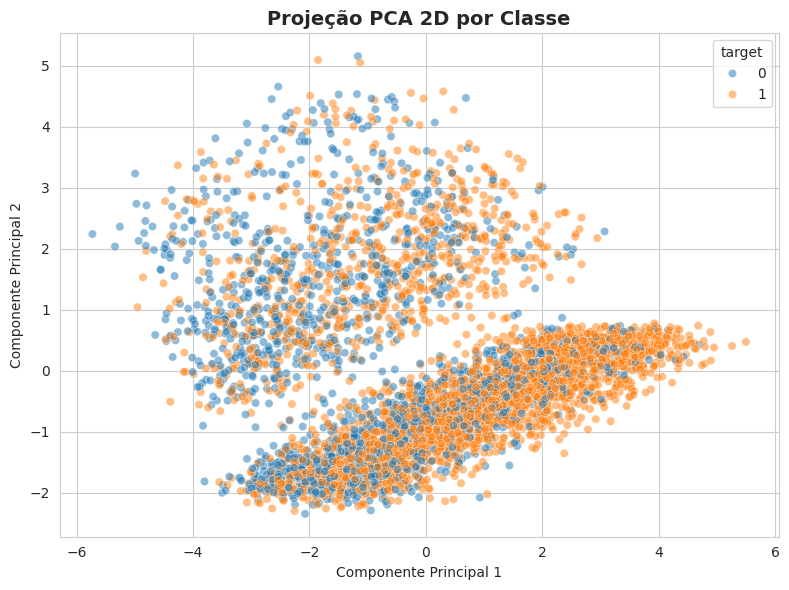

In [23]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
pca_df['cluster'] = kmeans.fit_predict(pca_df[['PC1', 'PC2', 'PC3']])

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df.sample(min(5000, len(pca_df)), random_state=RANDOM_STATE),
    x='PC1', y='PC2', hue='target', alpha=0.5
)
plt.title('Projeção PCA 2D por Classe', fontsize=14, weight='bold')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.tight_layout()
plt.show()

**Interpretação:**  
A projeção em duas dimensões permite observar se existe alguma organização estrutural nos dados que favoreça a separação das classes.

.

In [24]:
# Versão mais limpa Gráfico em 3D

sample_pca = pca_df.sample(min(2000, len(pca_df)), random_state=RANDOM_STATE).copy()

sample_pca['target_label'] = sample_pca['target'].map({
    0: 'Não Conversão',
    1: 'Conversão'
})

fig = px.scatter_3d(
    sample_pca,
    x='PC1',
    y='PC2',
    z='PC3',
    color='target_label',
    title='Projeção PCA 3D por Classe',
    labels={
        'PC1': 'Componente Principal 1',
        'PC2': 'Componente Principal 2',
        'PC3': 'Componente Principal 3',
        'target_label': 'Classe Real'
    },
    opacity=0.65,
    template='plotly_white',
    color_discrete_map={
        'Não Conversão': '#1f4aa8',  # azul mais forte
        'Conversão': '#c0392b'       # vermelho mais forte
    }
)

fig.update_traces(marker=dict(size=3))

fig.update_layout(
    width=1050,
    height=680,
    legend=dict(
        title='Classe Real',
        font=dict(size=16, color='black'),
        title_font=dict(size=16, color='black'),
        bgcolor='rgba(240,240,240,0.96)',   # cinza suave
        bordercolor='rgba(70,70,70,0.85)',  # borda escura
        borderwidth=2,
        x=0.98,
        y=0.98,
        xanchor='right',
        yanchor='top'
    ),
    scene=dict(
        xaxis=dict(title='PC1', backgroundcolor='rgb(245,245,245)'),
        yaxis=dict(title='PC2', backgroundcolor='rgb(245,245,245)'),
        zaxis=dict(title='PC3', backgroundcolor='rgb(245,245,245)'),
        camera=dict(eye=dict(x=1.7, y=1.4, z=1.0))
    ),
    margin=dict(l=0, r=0, t=55, b=0)
)

fig.show()

.

In [25]:
# Versão Completa do gráfico 3D

sample_pca = pca_df.sample(min(2500, len(pca_df)), random_state=RANDOM_STATE).copy()

sample_pca['target_label'] = sample_pca['target'].map({
    0: 'Não Conversão',
    1: 'Conversão'
})

fig = px.scatter_3d(
    sample_pca,
    x='PC1',
    y='PC2',
    z='PC3',
    color='target_label',
    title='Projeção PCA 3D por Classe',
    labels={
        'PC1': 'Componente Principal 1',
        'PC2': 'Componente Principal 2',
        'PC3': 'Componente Principal 3',
        'target_label': 'Classe Real'
    },
    opacity=0.75
)

fig.update_traces(
    marker=dict(size=4)
)

fig.update_layout(
    width=1050,
    height=680,
    legend=dict(
        title='Classe Real',
        font=dict(size=16, color='black'),
        title_font=dict(size=16, color='black'),
        bgcolor='rgba(240,240,240,0.96)',   # cinza suave
        bordercolor='rgba(70,70,70,0.85)',  # borda escura
        borderwidth=2,
        x=0.98,
        y=0.98,
        xanchor='right',
        yanchor='top'
    ),
    scene=dict(
        xaxis=dict(title='PC1', backgroundcolor='rgb(245,245,245)'),
        yaxis=dict(title='PC2', backgroundcolor='rgb(245,245,245)'),
        zaxis=dict(title='PC3', backgroundcolor='rgb(245,245,245)'),
        camera=dict(eye=dict(x=1.7, y=1.4, z=1.0))
    ),
    margin=dict(l=0, r=0, t=55, b=0)
)

fig.show()

**Nota metodológica:**  
Foram avaliadas duas versões da visualização PCA 3D: uma versão mais completa, com maior densidade de pontos e detalhamento visual, e uma versão mais limpa, priorizando clareza interpretativa. Para a apresentação principal, optou-se pela versão mais limpa, por favorecer a leitura visual e reduzir sobreposição entre os registros.

.

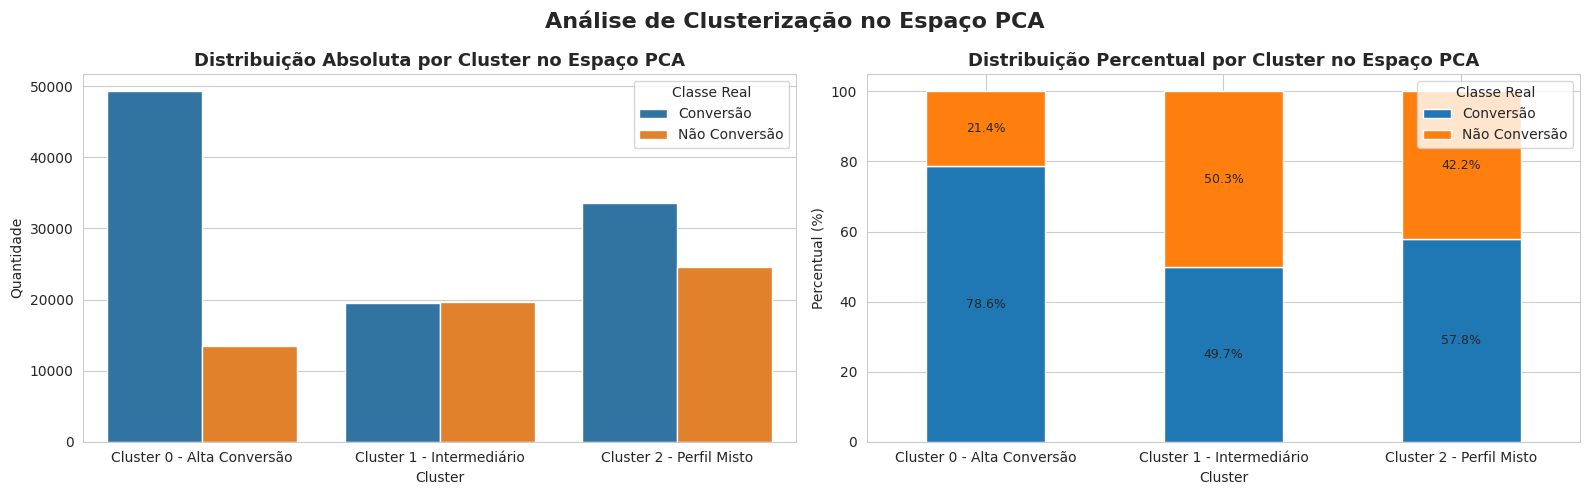

In [26]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(pca_df[['PC1', 'PC2', 'PC3']])

data_pca_df = pca_df.copy()
data_pca_df['cluster'] = clusters

data_pca_df['cluster_label'] = data_pca_df['cluster'].map({
    0: 'Cluster 0 - Alta Conversão',
    1: 'Cluster 1 - Intermediário',
    2: 'Cluster 2 - Perfil Misto'
})

ordem_clusters = [
    'Cluster 0 - Alta Conversão',
    'Cluster 1 - Intermediário',
    'Cluster 2 - Perfil Misto'
]

data_pca_df['cluster_label'] = pd.Categorical(
    data_pca_df['cluster_label'],
    categories=ordem_clusters,
    ordered=True
)

data_pca_df['target_label'] = data_pca_df['target'].map({
    0: 'Não Conversão',
    1: 'Conversão'
})

# Tabelas auxiliares
cluster_target_ct = pd.crosstab(
    data_pca_df['cluster_label'],
    data_pca_df['target_label']
).reindex(ordem_clusters)

cluster_target_pct = cluster_target_ct.div(cluster_target_ct.sum(axis=1), axis=0) * 100

# Figura com dois gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1) Quantidade absoluta
sns.countplot(
    data=data_pca_df,
    x='cluster_label',
    hue='target_label',
    order=ordem_clusters,
    ax=axes[0]
)
axes[0].set_title('Distribuição Absoluta por Cluster no Espaço PCA', fontsize=13, weight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Quantidade')
axes[0].legend(title='Classe Real')

# 2) Percentual empilhado
cluster_target_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1]
)
axes[1].set_title('Distribuição Percentual por Cluster no Espaço PCA', fontsize=13, weight='bold')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Percentual (%)')
axes[1].legend(title='Classe Real')
axes[1].tick_params(axis='x', rotation=0)

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center', fontsize=9)

plt.suptitle('Análise de Clusterização no Espaço PCA', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

### Fechamento da Análise com PCA

A redução de dimensionalidade por meio do PCA mostrou que os dados apresentam estrutura exploratória útil para apoio à análise visual e à identificação de padrões de agrupamento. Essa etapa agregou valor interpretativo ao projeto ao complementar a compreensão do comportamento da base. Ainda assim, a predição final foi conduzida por modelagem supervisionada, que oferece maior aderência ao objetivo principal de estimar a probabilidade de conversão dos agendamentos.

.

## 9. Comparação Inicial de Modelos

Nesta etapa, foram comparados algoritmos de classificação com o objetivo de avaliar seu desempenho médio em validação cruzada e selecionar a alternativa mais adequada para o problema.

Para melhorar a leitura visual, os comparativos foram apresentados em gráficos de pontos horizontais, que permitem comparar desempenho e custo computacional sem repetir muitos gráficos de barras ao longo do notebook.


### Justificativa dos algoritmos avaliados

Os modelos escolhidos representam abordagens complementares para o problema de conversão:

- **Logistic Regression:** baseline forte para classificação binária, com boa interpretabilidade e geração direta de probabilidades;
- **Random Forest:** capaz de capturar interações e relações não lineares entre variáveis;
- **XGBoost / Gradient Boosting:** benchmark mais competitivo para dados tabulares, útil para testar ganho preditivo frente a modelos mais simples.

Essa comparação permite equilibrar **desempenho, interpretabilidade e custo computacional**, pontos importantes para um cenário aplicado como o da MaterDei.

In [27]:
models = {
    'LogisticRegression': LogisticRegression(
        max_iter=300,
        class_weight='balanced',
        solver='saga',
        C=1.0,
        penalty='l2',
        random_state=RANDOM_STATE
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight='balanced_subsample'
    )
}

# Modelo adicional para fortalecer benchmark
try:
    from xgboost import XGBClassifier
    models['XGBoost'] = XGBClassifier(
        n_estimators=120,
        max_depth=4,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=1
    )
    print('XGBoost disponível e incluído no benchmark.')
except Exception:
    models['GradientBoosting'] = GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.08,
        max_depth=3,
        random_state=RANDOM_STATE
    )
    print('XGBoost não disponível. GradientBoosting incluído no benchmark.')

XGBoost disponível e incluído no benchmark.


.

In [28]:
results = []
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    t_model_start = time.time()
    scores = cross_validate(
        pipe,
        X_tune,
        y_tune,
        cv=cv,
        scoring={'auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall'},
        n_jobs=1,
        return_train_score=True
    )
    elapsed = time.time() - t_model_start

    results.append({
        'modelo': name,
        'auc_cv_mean': np.mean(scores['test_auc']),
        'f1_cv_mean': np.mean(scores['test_f1']),
        'recall_cv_mean': np.mean(scores['test_recall']),
        'auc_train_mean': np.mean(scores['train_auc']),
        'tempo_segundos': elapsed
    })

results_df = pd.DataFrame(results).sort_values(
    ['auc_cv_mean', 'f1_cv_mean', 'recall_cv_mean'],
    ascending=False
).reset_index(drop=True)

display(results_df)

,modelo,auc_cv_mean,f1_cv_mean,recall_cv_mean,auc_train_mean,tempo_segundos
0,LogisticRegression,0.698841,0.696614,0.641752,0.705282,22.492655
1,XGBoost,0.692930,0.772757,0.865365,0.768628,4.031906
2,RandomForest,0.691238,0.714146,0.689914,0.916952,10.254486


.

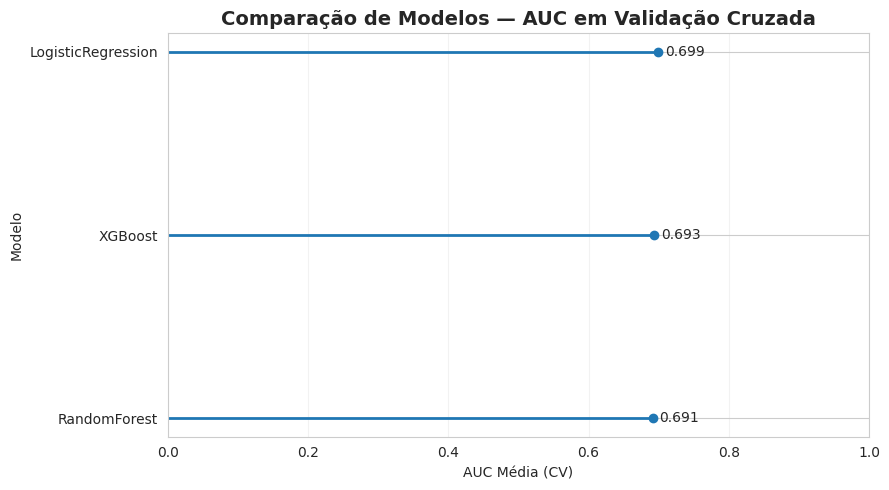

In [29]:
auc_plot = results_df.sort_values('auc_cv_mean', ascending=True).reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.hlines(y=auc_plot['modelo'], xmin=0, xmax=auc_plot['auc_cv_mean'], linewidth=2)
plt.plot(auc_plot['auc_cv_mean'], auc_plot['modelo'], 'o')
plt.title('Comparação de Modelos — AUC em Validação Cruzada', fontsize=14, weight='bold')
plt.xlabel('AUC Média (CV)')
plt.ylabel('Modelo')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.25)

for y, x in enumerate(auc_plot['auc_cv_mean']):
    plt.text(x + 0.01, y, f'{x:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()


**Interpretação:**  
A AUC mede a capacidade do modelo de separar corretamente as classes ao longo de diferentes limiares de decisão.

.

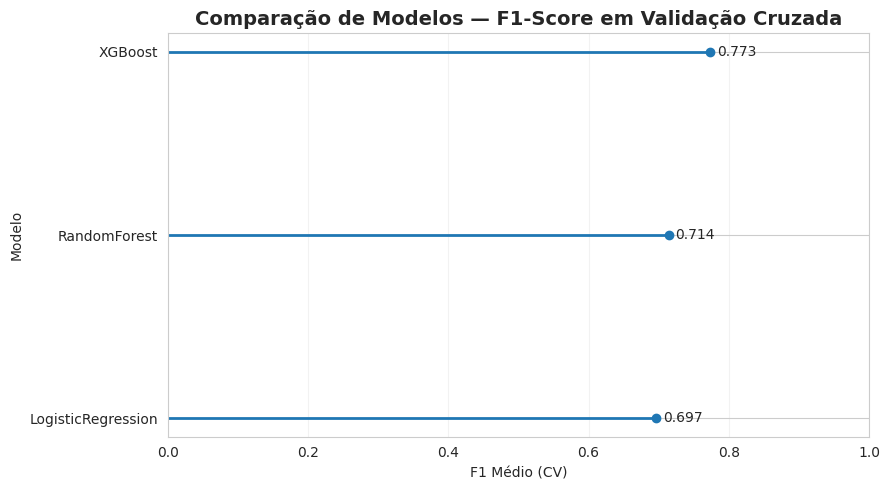

In [30]:
f1_plot = results_df.sort_values('f1_cv_mean', ascending=True).reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.hlines(y=f1_plot['modelo'], xmin=0, xmax=f1_plot['f1_cv_mean'], linewidth=2)
plt.plot(f1_plot['f1_cv_mean'], f1_plot['modelo'], 'o')
plt.title('Comparação de Modelos — F1-Score em Validação Cruzada', fontsize=14, weight='bold')
plt.xlabel('F1 Médio (CV)')
plt.ylabel('Modelo')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.25)

for y, x in enumerate(f1_plot['f1_cv_mean']):
    plt.text(x + 0.01, y, f'{x:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()


**Interpretação:**  
O F1-score resume o equilíbrio entre precisão e recall, sendo especialmente útil quando os erros possuem impactos diferentes.

.

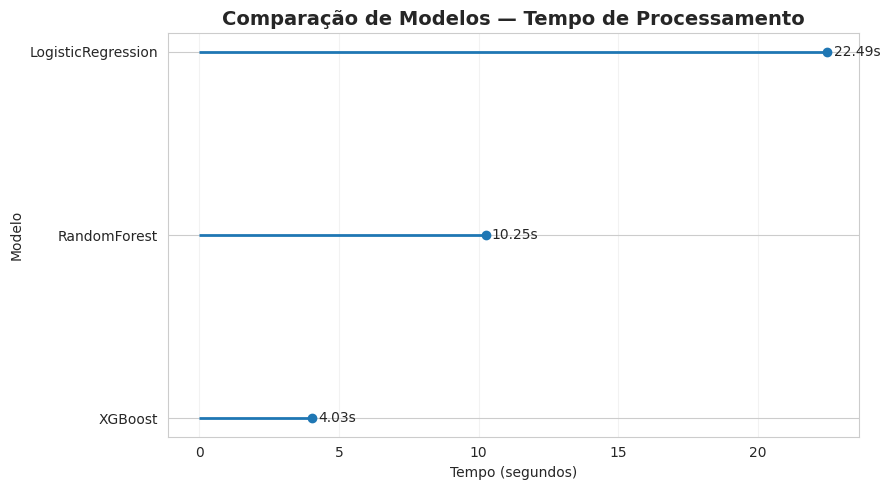

In [31]:
tempo_plot = results_df.sort_values('tempo_segundos', ascending=True).reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.hlines(y=tempo_plot['modelo'], xmin=0, xmax=tempo_plot['tempo_segundos'], linewidth=2)
plt.plot(tempo_plot['tempo_segundos'], tempo_plot['modelo'], 'o')
plt.title('Comparação de Modelos — Tempo de Processamento', fontsize=14, weight='bold')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Modelo')
plt.grid(axis='x', alpha=0.25)

for y, x in enumerate(tempo_plot['tempo_segundos']):
    plt.text(x + max(tempo_plot['tempo_segundos']) * 0.01, y, f'{x:.2f}s', va='center', fontsize=10)

plt.tight_layout()
plt.show()


.

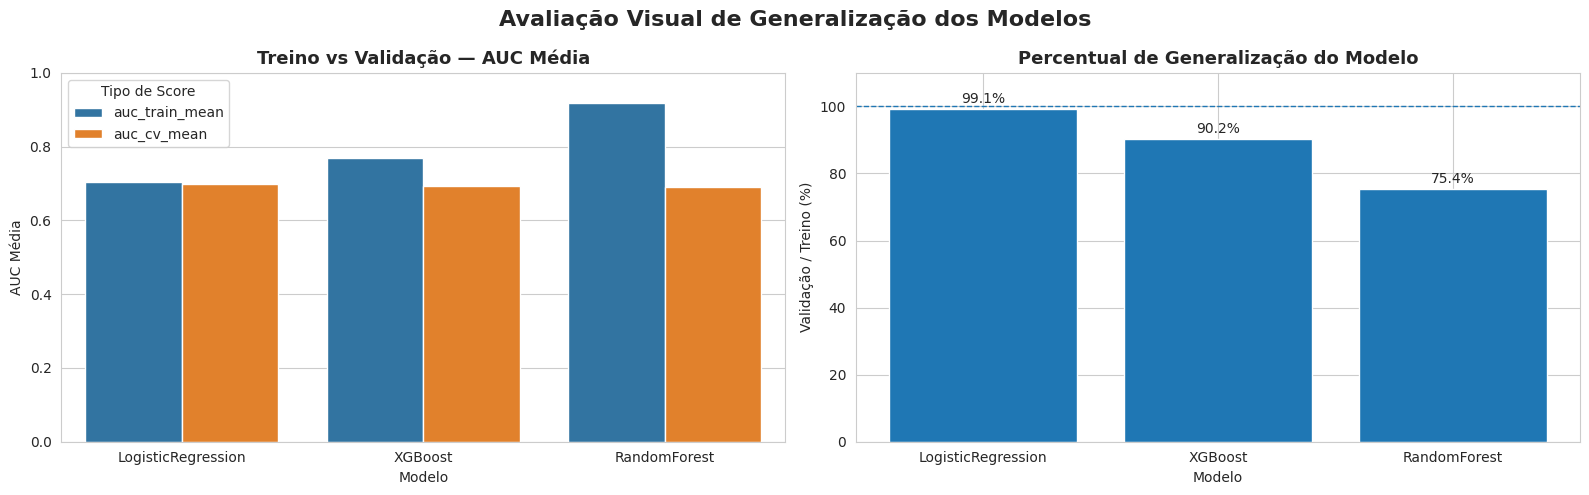

In [32]:
cv_plot_df = results_df.melt(
    id_vars='modelo',
    value_vars=['auc_train_mean', 'auc_cv_mean'],
    var_name='tipo_score',
    value_name='valor'
)

# Percentual de generalização
generalizacao_df = results_df.copy()
generalizacao_df['percentual_generalizacao'] = (
    generalizacao_df['auc_cv_mean'] / generalizacao_df['auc_train_mean']
) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Barras agrupadas - treino vs validação
sns.barplot(
    data=cv_plot_df,
    x='modelo',
    y='valor',
    hue='tipo_score',
    ax=axes[0]
)
axes[0].set_title('Treino vs Validação — AUC Média', fontsize=13, weight='bold')
axes[0].set_xlabel('Modelo')
axes[0].set_ylabel('AUC Média')
axes[0].set_ylim(0, 1)
axes[0].legend(title='Tipo de Score')

# 2. Percentual de generalização
bars = axes[1].bar(
    generalizacao_df['modelo'],
    generalizacao_df['percentual_generalizacao']
)
axes[1].set_title('Percentual de Generalização do Modelo', fontsize=13, weight='bold')
axes[1].set_xlabel('Modelo')
axes[1].set_ylabel('Validação / Treino (%)')
axes[1].set_ylim(0, 110)
axes[1].axhline(100, linestyle='--', linewidth=1)

for bar in bars:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.suptitle('Avaliação Visual de Generalização dos Modelos', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

**Interpretação:**  
Além da capacidade preditiva, o custo computacional também é um critério relevante na escolha do modelo, especialmente em cenários de maior escala ou com necessidade de reprocessamento frequente. Por isso, a comparação entre desempenho e tempo de execução torna a decisão metodológica mais robusta e equilibrada.

Adicionalmente, a análise comparativa entre os resultados de treino e validação permite verificar a capacidade de generalização dos algoritmos. Quanto menor a diferença entre esses dois desempenhos, maior tende a ser a estabilidade do modelo em dados não vistos, reduzindo indícios de overfitting.

### Fechamento da Comparação de Modelos

A comparação inicial permitiu identificar diferenças relevantes entre os algoritmos avaliados, tanto em desempenho quanto em custo computacional.




.

## 10. Otimização de hiperparâmetros

A etapa de tuning foi mantida em regressão logística para preservar interpretabilidade e estabilidade, sem abrir mão de um ajuste fino dos parâmetros.

In [33]:
best_candidate_name = results_df.loc[0, 'modelo']
print('Melhor candidato pelo benchmark:', best_candidate_name)

log_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=500,
        class_weight='balanced',
        solver='saga',
        random_state=RANDOM_STATE
    ))
])

param_dist = {
    'model__C': [0.01, 0.1, 1, 3, 10],
    'model__penalty': ['l1', 'l2']
}

search = RandomizedSearchCV(
    log_pipe,
    param_distributions=param_dist,
    n_iter=6,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=1
)

t_tune = time.time()
search.fit(X_tune, y_tune)
t_tune = time.time() - t_tune

print('Melhor score AUC CV:', round(search.best_score_, 4))
print('Melhores parâmetros:', search.best_params_)
print(f'Tempo total de tuning: {t_tune:.2f} segundos')

best_model = search.best_estimator_

Melhor candidato pelo benchmark: LogisticRegression
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Melhor score AUC CV: 0.6996
Melhores parâmetros: {'model__penalty': 'l1', 'model__C': 0.1}
Tempo total de tuning: 95.67 segundos


**Interpretação:**  
A otimização foi conduzida com `RandomizedSearchCV`, técnica apropriada para explorar combinações de hiperparâmetros de forma eficiente. O critério de seleção foi a **AUC-ROC**, por ser uma métrica robusta para avaliar separação entre classes em diferentes limiares.

.

## 11. Treinamento final no conjunto completo

In [34]:
t_fit_final = time.time()
best_model.fit(X_train, y_train)
t_fit_final = time.time() - t_fit_final

print(f'Tempo de treino final no conjunto completo: {t_fit_final:.2f} segundos')

Tempo de treino final no conjunto completo: 14.13 segundos


## 12. Avaliação do Modelo Final

In [35]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    'AUC': roc_auc_score(y_test, y_prob),
    'F1': f1_score(y_test, y_pred),
    'Precisao': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'Accuracy': accuracy_score(y_test, y_pred)
}

metrics_df = pd.DataFrame(metrics, index=['resultado']).T
metrics_df.columns = ['Valor']
display(metrics_df.style.format({'Valor': '{:.4f}'}))

print(classification_report(y_test, y_pred))

,Valor
AUC,0.7078
F1,0.7020
Precisao,0.7685
Recall,0.6461
Accuracy,0.6492


              precision    recall  f1-score   support

           0       0.51      0.65      0.57     14420
           1       0.77      0.65      0.70     25580

    accuracy                           0.65     40000
   macro avg       0.64      0.65      0.64     40000
weighted avg       0.68      0.65      0.66     40000



**Interpretação:**  
As métricas consolidadas mostram o desempenho geral do modelo no conjunto de teste. A leitura combinada dessas medidas é mais robusta do que depender apenas de uma métrica isolada.

.

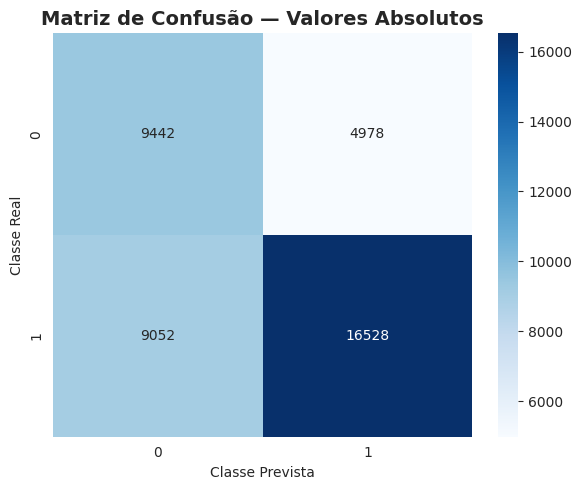

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão — Valores Absolutos', fontsize=14, weight='bold')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.tight_layout()
plt.show()

**Interpretação:**  
A matriz de confusão mostra como o modelo distribuiu seus acertos e erros em valores absolutos.

.

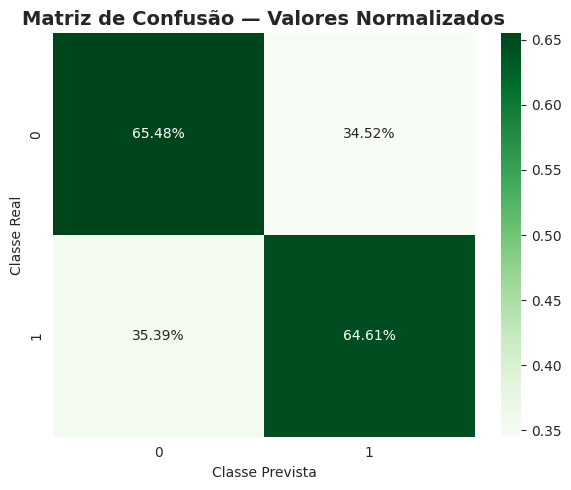

In [37]:
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')

plt.figure(figsize=(6, 5))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens')
plt.title('Matriz de Confusão — Valores Normalizados', fontsize=14, weight='bold')
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.tight_layout()
plt.show()

**Interpretação:**  
A versão normalizada facilita a leitura percentual dos acertos e erros por classe, melhorando a interpretação visual do recall.

.

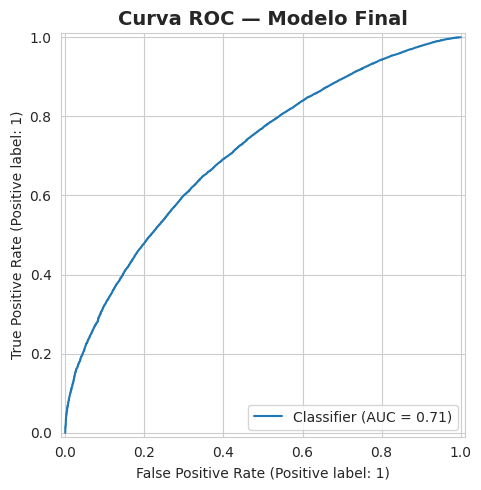

In [38]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title('Curva ROC — Modelo Final', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

**Interpretação:**  
A curva ROC avalia a capacidade discriminatória do modelo em diferentes limiares.

.


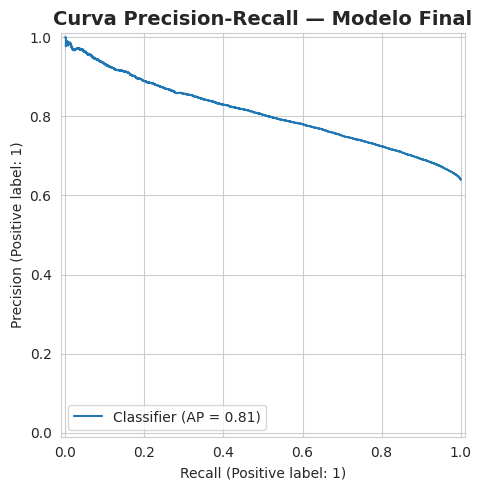

In [39]:
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title('Curva Precision-Recall — Modelo Final', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

**Interpretação:**  
A curva Precision-Recall é especialmente útil quando a classe positiva precisa de atenção especial em termos de sensibilidade e precisão.

.

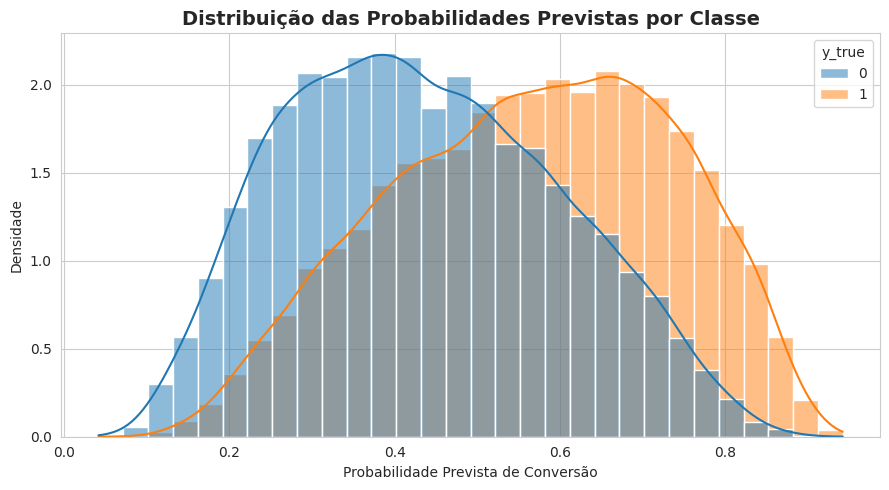

In [40]:
prob_df = pd.DataFrame({
    'y_true': y_test.values,
    'y_prob': y_prob
})

plt.figure(figsize=(9, 5))
sns.histplot(
    data=prob_df,
    x='y_prob',
    hue='y_true',
    bins=30,
    kde=True,
    stat='density',
    common_norm=False
)
plt.title('Distribuição das Probabilidades Previstas por Classe', fontsize=14, weight='bold')
plt.xlabel('Probabilidade Prevista de Conversão')
plt.ylabel('Densidade')
plt.tight_layout()
plt.show()

**Interpretação:**  
A distribuição das probabilidades previstas ajuda a verificar separação entre os grupos, sobreposição e confiança do modelo.

### Fechamento da Avaliação do Modelo Final

O modelo final apresentou desempenho consistente no conjunto de teste, com capacidade discriminatória adequada para apoiar a previsão de conversão.

.

## 12.1 Avaliação do Threshold de Decisão

,threshold,precision,recall,f1,taxa_fp,taxa_fn
0,0.35,0.7020,0.8722,0.7779,0.6569,0.1278
1,0.40,0.7228,0.8063,0.7623,0.5485,0.1937
2,0.45,0.7440,0.7278,0.7358,0.4442,0.2722
3,0.50,0.7685,0.6461,0.7020,0.3452,0.3539
4,0.55,0.7909,0.5503,0.6490,0.2581,0.4497
5,0.60,0.8175,0.4520,0.5821,0.1790,0.5480


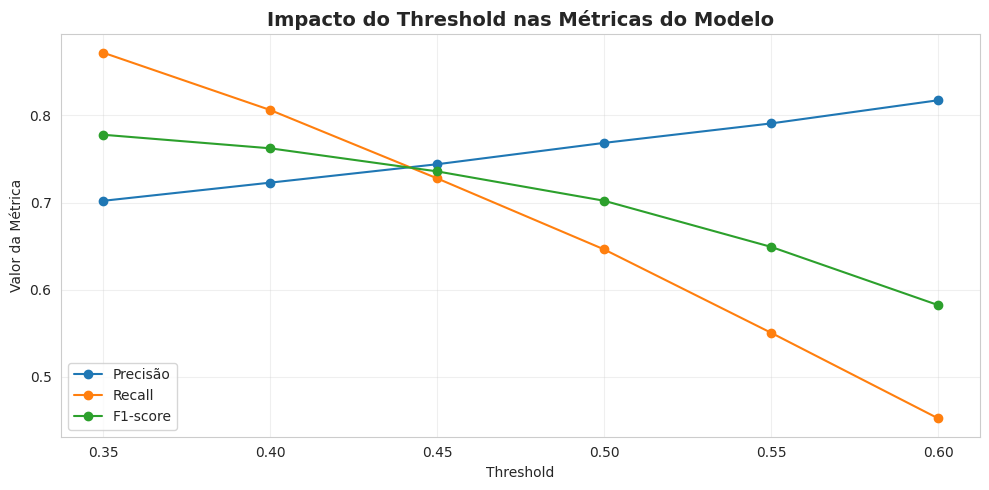

In [41]:
thresholds = [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_results = []

for th in thresholds:
    pred_th = (y_prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_th).ravel()
    threshold_results.append({
        'threshold': th,
        'precision': precision_score(y_test, pred_th),
        'recall': recall_score(y_test, pred_th),
        'f1': f1_score(y_test, pred_th),
        'taxa_fp': fp / (fp + tn),
        'taxa_fn': fn / (fn + tp)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

plt.figure(figsize=(10, 5))
plt.plot(threshold_df['threshold'], threshold_df['precision'], marker='o', label='Precisão')
plt.plot(threshold_df['threshold'], threshold_df['recall'], marker='o', label='Recall')
plt.plot(threshold_df['threshold'], threshold_df['f1'], marker='o', label='F1-score')
plt.title('Impacto do Threshold nas Métricas do Modelo', fontsize=14, weight='bold')
plt.xlabel('Threshold')
plt.ylabel('Valor da Métrica')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretação:**  
A análise de threshold mostra que a escolha do ponto de corte altera o equilíbrio entre precisão, recall e F1-score. O melhor threshold estatístico nem sempre é o melhor threshold de negócio.

### Fechamento da Avaliação de Threshold

A escolha do threshold deve considerar o impacto operacional do erro. Em cenários reais, essa decisão pode privilegiar maior sensibilidade ou maior precisão.

.

## 12.2 Valor de negócio — deciles, ganho acumulado e lift

In [42]:
gain_df = pd.DataFrame({
    'y_true': y_test.values,
    'y_prob': y_prob
}).sort_values('y_prob', ascending=False).reset_index(drop=True)

gain_df['decile'] = pd.qcut(gain_df.index + 1, 10, labels=[f'D{i}' for i in range(1, 11)])
gain_df['cum_positivos'] = gain_df['y_true'].cumsum()
total_positivos = gain_df['y_true'].sum()
gain_df['ganho_acumulado'] = gain_df['cum_positivos'] / total_positivos

decile_summary = gain_df.groupby('decile', observed=False).agg(
    registros=('y_true', 'size'),
    conversoes=('y_true', 'sum'),
    prob_media=('y_prob', 'mean')
).reset_index()

decile_summary['taxa_conversao'] = decile_summary['conversoes'] / decile_summary['registros']
decile_summary['lift'] = decile_summary['taxa_conversao'] / gain_df['y_true'].mean()

display(decile_summary.round(4))

,decile,registros,conversoes,prob_media,taxa_conversao,lift
0,D1,4000,3660,0.8109,0.9150,1.4308
1,D2,4000,3258,0.7219,0.8145,1.2737
2,D3,4000,3068,0.6596,0.7670,1.1994
3,D4,4000,2867,0.6022,0.7168,1.1208
4,D5,4000,2701,0.5472,0.6752,1.0559
5,D6,4000,2447,0.4931,0.6118,0.9566
6,D7,4000,2326,0.4361,0.5815,0.9093
7,D8,4000,2084,0.3779,0.5210,0.8147
8,D9,4000,1856,0.3113,0.4640,0.7256
9,D10,4000,1313,0.2167,0.3282,0.5133


.

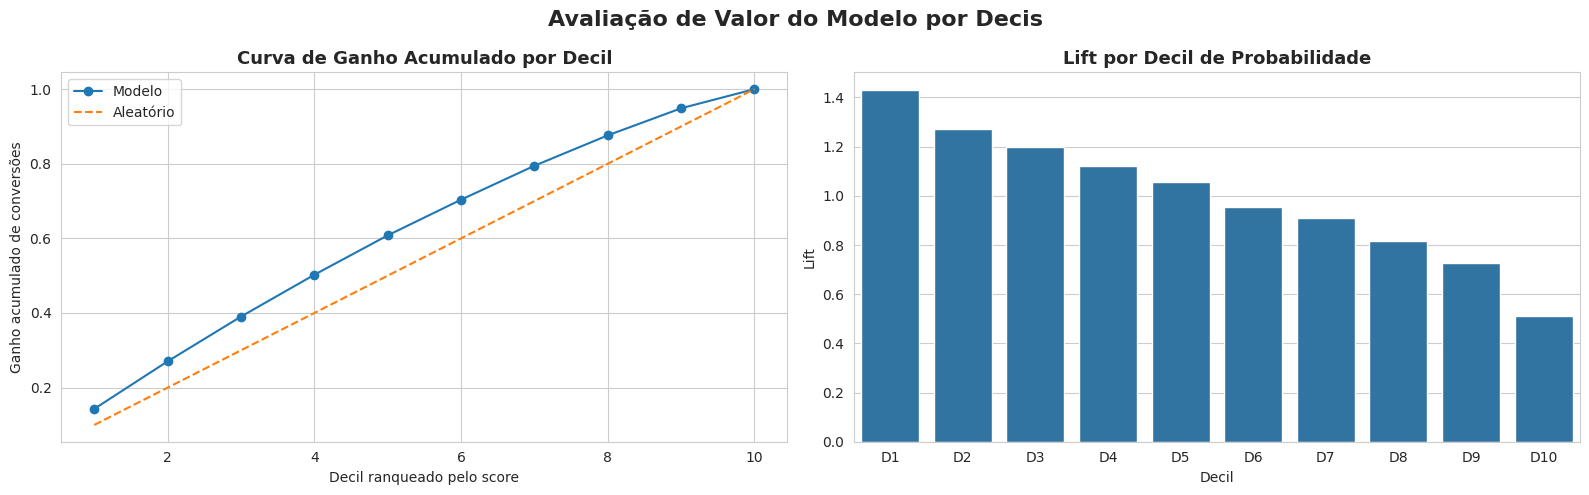

In [43]:
cum_by_decile = gain_df.groupby('decile', observed=False)['y_true'].sum().cumsum().reset_index()
cum_by_decile['ganho_acumulado'] = cum_by_decile['y_true'] / gain_df['y_true'].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Curva de ganho acumulado
axes[0].plot(
    range(1, len(cum_by_decile) + 1),
    cum_by_decile['ganho_acumulado'],
    marker='o',
    label='Modelo'
)
axes[0].plot(
    range(1, len(cum_by_decile) + 1),
    np.linspace(0.1, 1.0, len(cum_by_decile)),
    linestyle='--',
    label='Aleatório'
)
axes[0].set_title('Curva de Ganho Acumulado por Decil', fontsize=13, weight='bold')
axes[0].set_xlabel('Decil ranqueado pelo score')
axes[0].set_ylabel('Ganho acumulado de conversões')
axes[0].legend()

# 2. Lift por decil
sns.barplot(
    data=decile_summary,
    x='decile',
    y='lift',
    ax=axes[1]
)
axes[1].set_title('Lift por Decil de Probabilidade', fontsize=13, weight='bold')
axes[1].set_xlabel('Decil')
axes[1].set_ylabel('Lift')

plt.suptitle('Avaliação de Valor do Modelo por Decis', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

**Interpretação:**  
As curvas de ganho e lift mostram se o modelo consegue concentrar os casos mais prováveis nos primeiros grupos ranqueados. Isso conecta a modelagem ao valor prático de priorização.

.

## 12.3 Estabilidade por segmento

In [44]:
segment_candidates = ['especialidade', 'canal_agendamento', 'urgencia', 'faixa_idade_ml', 'unidade']
segment_candidates = [c for c in segment_candidates if c in X_test.columns or c in df.columns]

segment_results = []

# base auxiliar com atributos do teste
seg_base = X_test.copy()
seg_base['y_true'] = y_test.values
seg_base['y_prob'] = y_prob
seg_base['y_pred'] = y_pred

if 'faixa_idade_ml' not in seg_base.columns and 'faixa_idade_ml' in df.columns:
    seg_base['faixa_idade_ml'] = df.loc[seg_base.index, 'faixa_idade_ml']

for seg_col in segment_candidates:
    tmp = seg_base[[seg_col, 'y_true', 'y_prob', 'y_pred']].copy()
    counts = tmp[seg_col].value_counts(dropna=False)

    valid_groups = counts[counts >= 200].index

    for grp in valid_groups:
        grp_df = tmp[tmp[seg_col] == grp]
        if grp_df['y_true'].nunique() < 2:
            continue

        segment_results.append({
            'segmento': seg_col,
            'grupo': grp,
            'n': len(grp_df),
            'auc': roc_auc_score(grp_df['y_true'], grp_df['y_prob']),
            'precision': precision_score(grp_df['y_true'], grp_df['y_pred'], zero_division=0),
            'recall': recall_score(grp_df['y_true'], grp_df['y_pred'], zero_division=0)
        })

segment_df = pd.DataFrame(segment_results)
display(segment_df.sort_values(['segmento', 'auc'], ascending=[True, False]).head(20))

,segmento,grupo,n,auc,precision,recall
8,canal_agendamento,WhatsApp,12495,0.714447,0.784481,0.749390
12,canal_agendamento,Presencial,5084,0.704048,0.762663,0.647818
11,canal_agendamento,Site,6067,0.702883,0.757192,0.547725
10,canal_agendamento,App,6398,0.702602,0.777542,0.689040
9,canal_agendamento,Telefone,9956,0.686925,0.739666,0.522720
2,especialidade,Ortopedia,5062,0.715753,0.760690,0.641163
0,especialidade,Dermatologia,5107,0.714116,0.771885,0.654450
6,especialidade,Cardiologia,4900,0.710638,0.780441,0.648230
5,especialidade,Pediatria,4944,0.708452,0.766418,0.654766
7,especialidade,Ginecologia,4888,0.707953,0.776588,0.647941


.

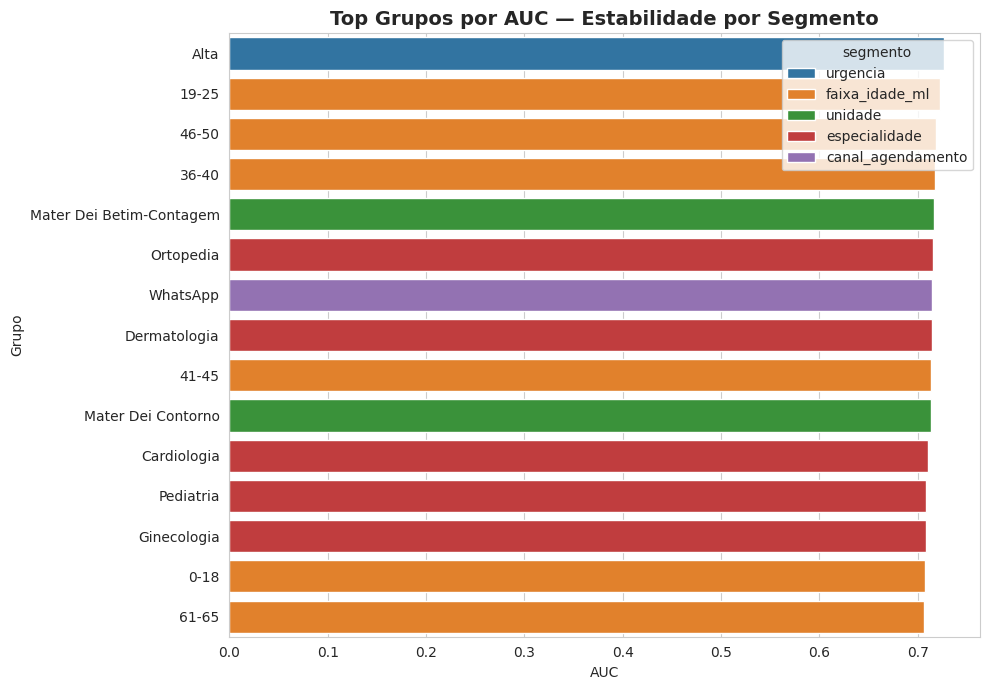

In [45]:
if not segment_df.empty:
    plot_seg = segment_df.sort_values('auc', ascending=False).head(15)
    plt.figure(figsize=(10, 7))
    sns.barplot(data=plot_seg, y='grupo', x='auc', hue='segmento')
    plt.title('Top Grupos por AUC — Estabilidade por Segmento', fontsize=14, weight='bold')
    plt.xlabel('AUC')
    plt.ylabel('Grupo')
    plt.tight_layout()
    plt.show()
else:
    print('Nenhum segmento elegível para análise com mínimo de 200 registros e duas classes.')

**Interpretação:**  
A análise segmentada mostra que o desempenho do modelo não é necessariamente homogêneo entre todos os grupos. Isso é importante para uma visão mais realista de produção.

.

## 12.4 Janela temporal da previsão

Abaixo, um experimento simples compara três cenários operacionais:
- **T-24h**: exclui `confirmou_4h` e `confirmou_2h`;
- **T-4h**: exclui apenas `confirmou_2h`;
- **T-2h**: usa todas as confirmações disponíveis.

,janela,auc
0,Modelo T-24h,0.7065
1,Modelo T-4h,0.7065
2,Modelo T-2h,0.7065


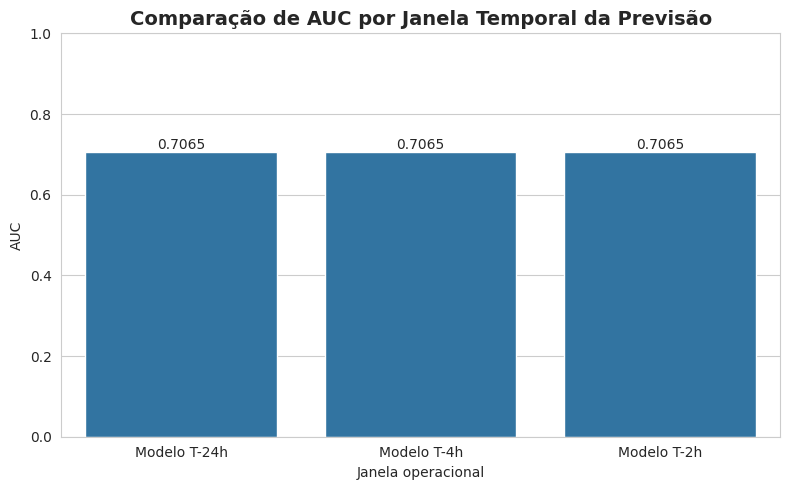

In [46]:
# Recria a variável alvo original para evitar problemas caso `y` tenha sido sobrescrita
if 'target' in globals() and isinstance(target, str) and target in df.columns:
    y_target = df[target].copy()
else:
    y_target = pd.concat([y_train, y_test]).sort_index()

def train_window_model(excluded_cols):
    X_window = X.copy().drop(columns=[c for c in excluded_cols if c in X.columns])
    cat_cols = X_window.select_dtypes(include=['object', 'category']).columns.tolist()
    num_cols = X_window.select_dtypes(include=['number', 'bool']).columns.tolist()

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_window, y_target,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_target
    )

    window_preprocessor = ColumnTransformer(
        transformers=[
            ('num', Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), num_cols),
            ('cat', Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01))
            ]), cat_cols)
        ]
    )

    window_model = Pipeline(steps=[
        ('preprocessor', window_preprocessor),
        ('model', LogisticRegression(
            max_iter=300,
            class_weight='balanced',
            solver='saga',
            C=search.best_params_['model__C'],
            penalty=search.best_params_['model__penalty'],
            random_state=RANDOM_STATE
        ))
    ])

    sss_local = StratifiedShuffleSplit(
        n_splits=1,
        train_size=min(30000, len(X_tr)),
        random_state=RANDOM_STATE
    )
    idx_local, _ = next(sss_local.split(X_tr, y_tr))
    X_tr_small = X_tr.iloc[idx_local]
    y_tr_small = y_tr.iloc[idx_local]

    window_model.fit(X_tr_small, y_tr_small)
    y_prob_local = window_model.predict_proba(X_te)[:, 1]

    return roc_auc_score(y_te, y_prob_local)

window_scenarios = {
    'Modelo T-24h': ['confirmou_4h', 'confirmou_2h'],
    'Modelo T-4h': ['confirmou_2h'],
    'Modelo T-2h': []
}

window_results = []
for name, excluded in window_scenarios.items():
    auc_value = train_window_model(excluded)
    window_results.append({'janela': name, 'auc': auc_value})

window_df = pd.DataFrame(window_results)
display(window_df.round(4))

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=window_df, x='janela', y='auc')
plt.title('Comparação de AUC por Janela Temporal da Previsão', fontsize=14, weight='bold')
plt.xlabel('Janela operacional')
plt.ylabel('AUC')
plt.ylim(0, 1)

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{h:.4f}', (p.get_x() + p.get_width()/2, h),
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

**Interpretação:**  
A performance do modelo varia conforme a janela temporal da previsão. Quanto mais próximo do evento, maior tende a ser a precisão, mas menor o tempo disponível para intervenção.

.

## 13. Interpretabilidade do Modelo

In [47]:
# nomes das features após transformação
ohe = best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_names = ohe.get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([numeric_features, cat_names])

coef = best_model.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({
    'feature': all_feature_names,
    'coef_abs': np.abs(coef),
    'coef': coef
}).sort_values('coef_abs', ascending=False).head(20)

display(coef_df)

,feature,coef_abs,coef
55,origem_agendamento_Retorno,0.306252,0.306252
4,faltas_anteriores,0.298142,-0.298142
62,urgencia_Alta,0.282309,0.282309
49,canal_agendamento_Telefone,0.244437,-0.244437
63,urgencia_Baixa,0.222191,-0.222191
2,dias_antecedencia,0.211763,-0.211763
15,dias_para_consulta_calc,0.211763,-0.211763
50,canal_agendamento_WhatsApp,0.210539,0.210539
48,canal_agendamento_Site,0.197138,-0.197138
54,origem_agendamento_Encaminhamento,0.180245,0.180245


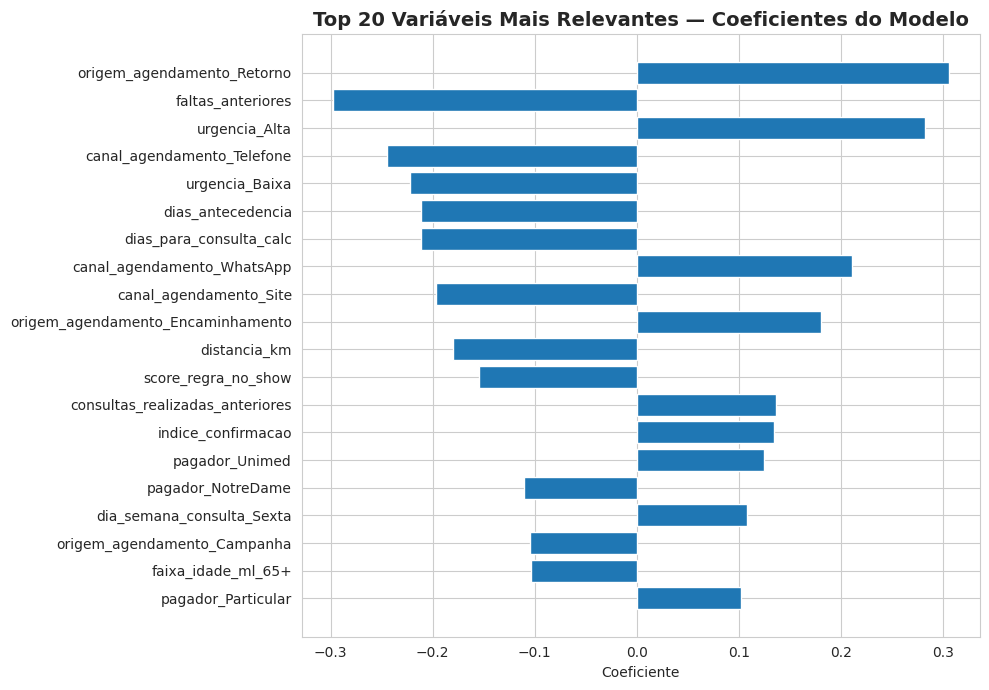

In [48]:
plt.figure(figsize=(10, 7))
plt.barh(coef_df['feature'][::-1], coef_df['coef'][::-1])
plt.title('Top 20 Variáveis Mais Relevantes — Coeficientes do Modelo', fontsize=14, weight='bold')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()

**Interpretação:**  
Os coeficientes ajudam a entender quais variáveis exercem maior influência na decisão da regressão logística, tanto em intensidade quanto em direção.

.

In [49]:
# Permutation importance corrigida:
# a importância por permutação do pipeline usa o espaço original de entrada,
# portanto os nomes corretos são as colunas originais de X_test_sample.

X_test_sample = X_test.sample(min(5000, len(X_test)), random_state=RANDOM_STATE)
y_test_sample = y_test.loc[X_test_sample.index]

perm = permutation_importance(
    best_model,
    X_test_sample,
    y_test_sample,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring='roc_auc'
)

perm_df = pd.DataFrame({
    'feature': X_test_sample.columns,
    'importance': perm.importances_mean
}).sort_values('importance', ascending=False).head(20)

display(perm_df)

,feature,importance
16,faltas_anteriores,0.036617
15,distancia_km,0.012398
8,canal_agendamento,0.011831
12,dias_antecedencia,0.011666
27,dias_para_consulta_calc,0.011666
11,urgencia,0.009984
9,origem_agendamento,0.008907
22,score_regra_no_show,0.006856
17,consultas_realizadas_anteriores,0.005561
10,pagador,0.004925


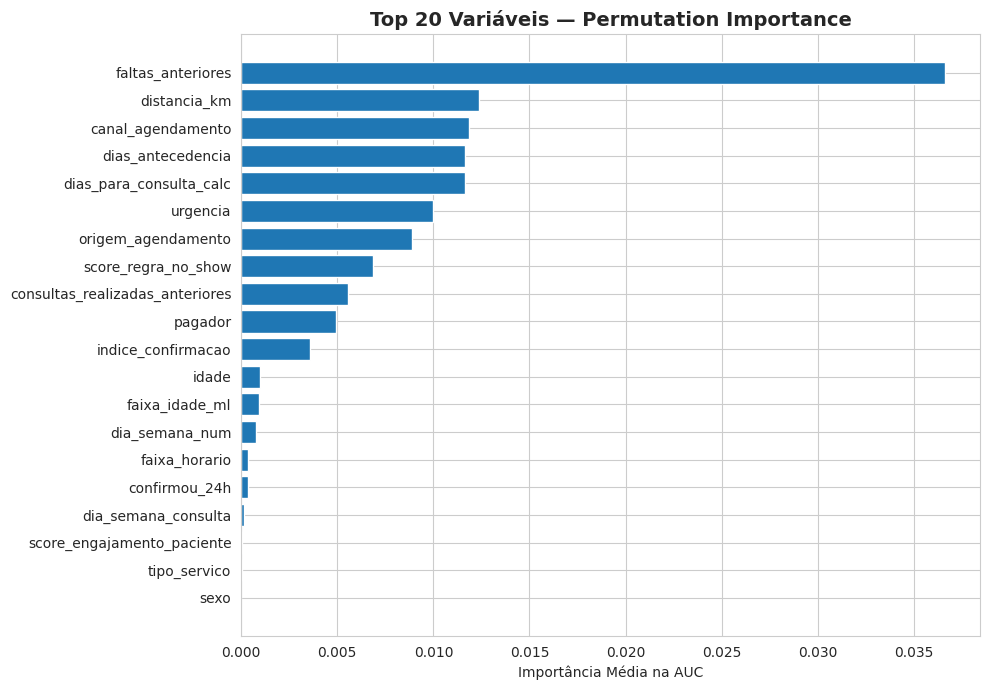

In [50]:
plt.figure(figsize=(10, 7))
plt.barh(perm_df['feature'][::-1], perm_df['importance'][::-1])
plt.title('Top 20 Variáveis — Permutation Importance', fontsize=14, weight='bold')
plt.xlabel('Importância Média na AUC')
plt.tight_layout()
plt.show()

**Interpretação:**  
A permutation importance mostra o impacto real de cada variável no desempenho do pipeline, medindo quanto a métrica piora quando o atributo é embaralhado.

.

In [51]:
# Leitura executiva das principais variáveis
top_features = perm_df['feature'].head(12).tolist()
print('Top variáveis pela permutation importance:')
for i, feat in enumerate(top_features, 1):
    print(f'{i:02d}. {feat}')

Top variáveis pela permutation importance:
01. faltas_anteriores
02. distancia_km
03. canal_agendamento
04. dias_antecedencia
05. dias_para_consulta_calc
06. urgencia
07. origem_agendamento
08. score_regra_no_show
09. consultas_realizadas_anteriores
10. pagador
11. indice_confirmacao
12. idade


### Fechamento da Interpretabilidade

A análise interpretativa mostrou que o modelo está apoiado em variáveis coerentes com o contexto do problema, especialmente histórico do paciente, engajamento e fatores operacionais.

.

## 14. Calibração das Probabilidades

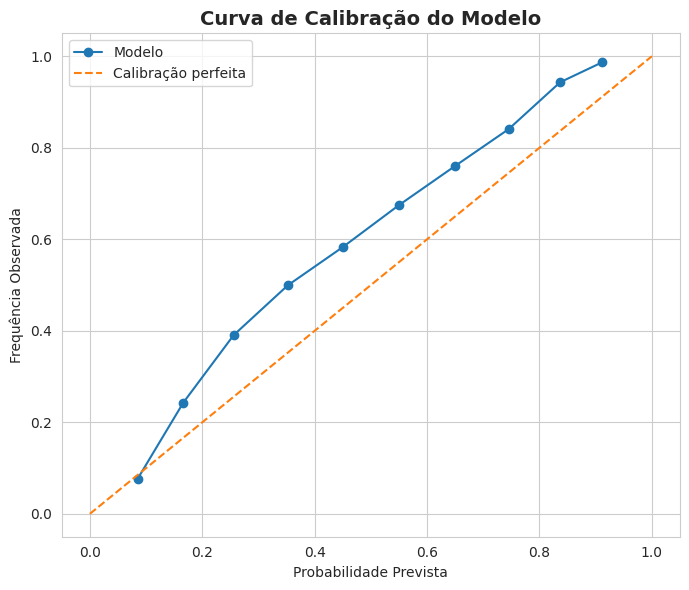

Brier Score: 0.2173


In [52]:
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

plt.figure(figsize=(7, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Modelo')
plt.plot([0, 1], [0, 1], linestyle='--', label='Calibração perfeita')
plt.title('Curva de Calibração do Modelo', fontsize=14, weight='bold')
plt.xlabel('Probabilidade Prevista')
plt.ylabel('Frequência Observada')
plt.legend()
plt.tight_layout()
plt.show()

print('Brier Score:', round(brier_score_loss(y_test, y_prob), 4))

**Interpretação:**  
A calibração avalia se as probabilidades emitidas pelo modelo são compatíveis com o comportamento real observado. Isso fortalece o uso do score para priorização.

### Fechamento da Calibração

A avaliação de calibração complementa a análise de desempenho tradicional ao verificar se a confiança do modelo está bem ajustada.

.

## 14.1 Função de predição para MVP local

In [53]:
def prever_probabilidade_conversao(novo_registro: pd.DataFrame, modelo=best_model) -> pd.DataFrame:
    probs = modelo.predict_proba(novo_registro)[:, 1]
    preds = modelo.predict(novo_registro)
    return pd.DataFrame({
        'probabilidade_conversao': probs,
        'classe_prevista': preds
    }, index=novo_registro.index)

exemplo = X_test.head(3).copy()
display(prever_probabilidade_conversao(exemplo))

,probabilidade_conversao,classe_prevista
104174,0.380704,0
67265,0.344017,0
97976,0.674208,1


.

## 14.2 Checklist final de aderência à rubrica de Machine Learning

### Itens atendidos neste notebook
- diagnóstico de valores ausentes com justificativa de imputação;
- tratamento explícito de outliers com evidência no código;
- criação de múltiplas novas features relevantes;
- codificação e normalização dentro de pipeline reprodutível;
- comparação e justificativa de múltiplos algoritmos;
- treino/teste e validação cruzada;
- otimização de hiperparâmetros com evidência;
- métricas adequadas ao contexto de conversão;
- interpretabilidade por coeficientes e permutation importance;
- função de predição para um MVP local.



.

## 15. Conclusões Finais

O projeto demonstrou que existe sinal preditivo relevante nos dados de agendamento, histórico, engajamento e contexto operacional, permitindo construir um modelo consistente para previsão de conversão.

Os principais achados podem ser resumidos em quatro pontos:
1. variáveis ligadas a histórico de faltas, engajamento e risco operacional tiveram papel importante na previsão;
2. o pipeline de pré-processamento tratou valores ausentes, outliers, codificação e normalização de forma adequada ao problema;
3. a comparação entre modelos, a validação cruzada e o tuning reforçaram a robustez da solução;
4. a avaliação final mostrou potencial prático para apoiar priorização operacional, confirmação inteligente e redução de perdas.

Como próximos passos, recomenda-se aprofundar o teste com modelos de boosting, revisar thresholds conforme a estratégia de negócio e integrar o score a fluxos automatizados da solução.
